<a href="https://colab.research.google.com/github/gustavokbb/TCC-CApA-2026-Deteccao-e-Classificacao/blob/main/01_Deteccao_Drones_YOLO11n_DUT_Anti_UAV.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# TCC CApA — Detecção de drones com YOLO11n

Este notebook reúne os experimentos de detecção de drones com o DUT Anti-UAV. O treinamento e os testes iniciais foram realizados em um computador portátil com CPU, fora do Google Colab. Os dados, modelos treinados e registros foram migrados para este ambiente para permitir a consulta pública e a reprodução dos experimentos.

O detector localiza a classe **UAV**, sem distinguir modelos de aeronave. A classificação com DenseNet201 é apresentada em outro notebook.

## Como utilizar

1. Para executar os códigos, entre em uma conta Google e siga as etapas abaixo. Se desejar guardar uma versão própria do notebook com suas alterações e resultados, utilize **Arquivo → Salvar uma cópia no Drive**. Essa cópia é opcional; visitantes com permissão de leitura não podem modificar a versão original.
2. Execute as seções **1 a 4**, na ordem, pelo botão ▶ à esquerda de cada célula. Aguarde a conclusão de cada etapa. O pacote é obtido por link público, sem autorizar acesso ao Drive para carregá-lo.
3. Consulte o histórico na **seção 5** ou execute a imagem de demonstração na **seção 7**. Não é necessário treinar novamente.
4. Para testes adicionais, use a **seção 6** (avaliação quantitativa), a **6.1** (três imagens externas), a **8** (arquivos próprios) ou a **9** (vídeo). Troque `False` por `True` apenas na opção que desejar executar.
5. Antes de encerrar a sessão, utilize a **seção 10** para baixar os resultados ou salvá-los no seu próprio Drive. Os arquivos temporários podem ser apagados ao encerrar o ambiente.

A **seção 11** permite iniciar um novo treinamento e permanece desativada por padrão. O notebook funciona em CPU; uma GPU disponível no Colab pode acelerar os testes.

## Experimentos originais

| Experimento | Épocas | Pasta de treinamento | Saídas históricas |
|---|---:|---|---|
| E1 | 1 | `train` | `predict` a `predict-5` |
| E2 | 10 | `train10` | `predict-6` a `predict-10` |
| E3 | 50 | `train50` | `predict-11` a `predict-15` |

## Limitações para interpretar os resultados

- Foram preservadas 5.200 imagens de treino, 2.600 de validação e 2.200 de teste.
- Uma imagem é idêntica no treino e no teste; portanto, o teste não é totalmente independente. Há também uma caixa de altura zero na validação e três arquivos de rótulos vazios no treino. As ocorrências estão registradas no manifesto, sem correção automática.
- `results.csv` contém métricas de **validação durante o treinamento**. A seção 6 produz uma avaliação separada.
- Imagens e vídeo externos permitem análise qualitativa. Confiança não equivale a acurácia, e a presença de caixas previstas não comprova detecção correta.
- Os novos testes registram seus parâmetros. Diferenças de configuração, bibliotecas ou dispositivo podem alterar resultados e tempos.


## 1. Preparar o ambiente

Execute a célula abaixo para instalar as bibliotecas e identificar o dispositivo disponível. A versão do Ultralytics é fixada em **8.4.53**, a mesma registrada nos treinamentos originais.

**CPU ou GPU: qual utilizar?**

- **CPU:** é suficiente para consultar os resultados salvos e testar o detector em poucas imagens, sem repetir o treinamento.
- **GPU:** pode reduzir bastante o tempo de processamento na avaliação do dataset, nos vídeos e, principalmente, para quem deseja **refazer o treinamento com o DUT Anti-UAV**, pela seção 11, em vez de apenas utilizar os modelos já treinados. O ganho de velocidade depende da GPU disponível e das configurações do experimento.

Para utilizar uma GPU, selecione **Ambiente de execução → Alterar o tipo de ambiente de execução → GPU**, caso esteja disponível, **antes de executar as células**. O código identifica e utiliza a GPU automaticamente; se não houver uma disponível, utiliza a CPU. O notebook também pode ser executado no plano gratuito, sujeito à disponibilidade e aos limites de recursos do Colab.

A GPU acelera os cálculos, mas não garante maior precisão. Os modelos treinados em CPU também podem ser utilizados em GPU. A seção 11 inicia um novo treinamento a partir dos pesos iniciais `yolo11n.pt`; não continua o treinamento dos arquivos `best.pt` dos experimentos.

**Aguarde a mensagem com a versão e o dispositivo antes de continuar.** Se houver conflito com uma versão já importada, reinicie a sessão e execute esta etapa novamente.

In [ ]:
import subprocess, sys
subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', 'ultralytics==8.4.53', 'gdown==5.2.0'])
import ultralytics, torch, pandas as pd, numpy as np, gdown
from pathlib import Path
from datetime import datetime, timezone
import json, hashlib, zipfile, shutil, uuid, platform, yaml, csv
from IPython.display import display, Image, Video
assert ultralytics.__version__ == '8.4.53', 'Reinicie a sessão para utilizar a versão indicada.'
DEVICE = '0' if torch.cuda.is_available() else 'cpu'
print('Ultralytics:', ultralytics.__version__, '| PyTorch:', torch.__version__, '| dispositivo:', DEVICE)


# Apresentação das matrizes: contagem e percentual, sem alterar a avaliação.
def figura_matriz_deteccao(contagens, normalizada=True):
    import matplotlib.pyplot as plt
    matriz = np.asarray(contagens, dtype=float).copy()
    totais = matriz.sum(axis=0, keepdims=True)
    proporcoes = np.divide(matriz, totais, out=np.zeros_like(matriz), where=totais != 0)
    cores = proporcoes if normalizada else matriz
    fig, ax = plt.subplots(figsize=(10, 8))
    imagem = ax.imshow(cores, cmap="Blues", vmin=0, interpolation="none")
    fig.colorbar(imagem, ax=ax, fraction=0.046, pad=0.05)
    for i in range(matriz.shape[0]):
        for j in range(matriz.shape[1]):
            cor = "white" if cores[i, j] > 0.45 * max(float(cores.max()), 1e-12) else "black"
            ax.text(j, i - 0.07, str(int(matriz[i, j])), ha="center", va="center", color=cor, fontsize=12)
            # A célula background/background não representa verdadeiros negativos.
            percentual = (f"{100 * proporcoes[i, j]:.2f}%".replace(".", ",")
                          if totais[0, j] and (i, j) != (matriz.shape[0]-1, matriz.shape[1]-1) else "—")
            ax.text(j, i + 0.10, percentual, ha="center", va="center", color=cor, fontsize=10)
    ax.set_xticks([0, 1], ["UAV", "background"])
    ax.set_yticks([0, 1], ["UAV", "background"])
    ax.set_xlabel("True")
    ax.set_ylabel("Predicted")
    ax.set_title("Confusion Matrix" + (" Normalized" if normalizada else ""))
    fig.text(0.5, 0.015,
             "Percentuais por coluna. background: erros de detecção; verdadeiros negativos não são contabilizados.\n"
             "—: percentual não aplicável ou coluna sem registros.",
             ha="center", fontsize=8)
    fig.tight_layout(rect=(0, 0.055, 1, 1))
    return fig

def salvar_matrizes_com_percentuais(contagens, destino):
    import matplotlib.pyplot as plt
    for normalizada, nome in [(False, "confusion_matrix.png"), (True, "confusion_matrix_normalized.png")]:
        figura = figura_matriz_deteccao(contagens, normalizada)
        figura.savefig(Path(destino) / nome, dpi=250, bbox_inches="tight")
        plt.close(figura)


Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.
Ultralytics: 8.4.53 | PyTorch: 2.11.0+cpu | dispositivo: cpu


## 2. Baixar o pacote público

Execute a próxima célula para baixar o DUT Anti-UAV, os modelos treinados e os arquivos necessários aos testes. O download utiliza um link público e grava os dados somente no ambiente temporário do Colab. **Não é necessário montar o Google Drive para esta etapa.**

O arquivo tem aproximadamente 1,4 GB. Aguarde a conclusão do download. Se o Google Drive indicar limite temporário de downloads, aguarde e tente novamente mais tarde; a permissão de acesso ao pacote não precisa ser alterada.

In [ ]:
PUBLIC_FILE_ID = '10bpF4M1Pxqb_ncGEK-h8ioZQPWwqfQmg'
EXPECTED_ZIP_SHA256 = '88a985221ef324cabc8a6eda140de1b86a548fe4f2a93c7525e16e31e996f41e'
def sha256_file(path):
    h = hashlib.sha256()
    with Path(path).open('rb') as f:
        for chunk in iter(lambda: f.read(4*1024*1024), b''):
            h.update(chunk)
    return h.hexdigest()
DOWNLOAD_DIR = Path('/content/tcc_deteccao_download')
DOWNLOAD_DIR.mkdir(exist_ok=True)
ZIP_LOCAL = DOWNLOAD_DIR/'DUT_Anti_UAV_Colab_Publico_v1.zip'
if not ZIP_LOCAL.is_file():
    downloaded = gdown.download(id=PUBLIC_FILE_ID, output=str(ZIP_LOCAL), quiet=False, use_cookies=False)
    assert downloaded is not None, 'Download indisponível. Verifique a conexão ou tente mais tarde.'
assert sha256_file(ZIP_LOCAL) == EXPECTED_ZIP_SHA256, 'Download incompleto ou diferente. Reinicie a sessão e tente novamente.'
print('Download público concluído e verificado:', ZIP_LOCAL.name)


Downloading...
From (original): https://drive.google.com/uc?id=10bpF4M1Pxqb_ncGEK-h8ioZQPWwqfQmg
From (redirected): https://drive.google.com/uc?id=10bpF4M1Pxqb_ncGEK-h8ioZQPWwqfQmg&confirm=t&uuid=069e819c-2a1b-4428-8fcd-e1050740ee53
To: /content/tcc_deteccao_download/DUT_Anti_UAV_Colab_Publico_v1.zip
100%|██████████| 1.42G/1.42G [00:23<00:00, 60.6MB/s]


Download público concluído e verificado: DUT_Anti_UAV_Colab_Publico_v1.zip


## 3. Verificar e extrair os dados

Esta etapa confere a integridade do pacote por SHA-256 e extrai seus arquivos. Também verifica as quantidades de imagens e rótulos em cada divisão.

**Execute a célula e aguarde a mensagem “Pacote íntegro”.** A conferência pode levar alguns minutos. Caso apareça uma falha de integridade, não avance: refaça o download da seção 2.

As anotações e divisões originais são preservadas. Os avisos exibidos identificam limitações conhecidas dos dados e não significam que os arquivos tenham sido alterados durante o download.

In [ ]:
WORK = Path('/content/tcc_deteccao_' + uuid.uuid4().hex[:8])
WORK.mkdir(exist_ok=False)
with zipfile.ZipFile(ZIP_LOCAL) as archive:
    for info in archive.infolist():
        target = (WORK/info.filename).resolve()
        assert target.is_relative_to(WORK.resolve()), 'Caminho inválido no pacote.'
    archive.extractall(WORK)
ROOT = WORK/'DUT_Anti_UAV'
MANIFEST = json.loads((ROOT/'manifesto.json').read_text())
for item in MANIFEST['files']:
    p = ROOT/item['path']
    assert p.stat().st_size == item['bytes'] and sha256_file(p) == item['sha256'], f"Falha de integridade: {p.name}"
for split, expected_count in MANIFEST['counts'].items():
    assert len(list((ROOT/split/'images').glob('*.jpg'))) == expected_count
    assert len(list((ROOT/split/'labels').glob('*.txt'))) == expected_count
print('Pacote íntegro. Divisões:', MANIFEST['counts'])
for issue in MANIFEST['issues']:
    print('ATENÇÃO:', issue)


Pacote íntegro. Divisões: {'train': 5200, 'val': 2600, 'test': 2200}
ATENÇÃO: Uma imagem idêntica em train/images/00259.jpg e test/images/01374.jpg; teste não totalmente independente.
ATENÇÃO: val/labels/00991.txt contém uma caixa com altura zero; também presente no XML original.
ATENÇÃO: Três arquivos de rótulos vazios no treino; verificar a presença de alvos antes de tratá-los como negativos.
ATENÇÃO: Os limiares dos testes históricos não constam nos arquivos de inferência; os novos testes registram seus próprios parâmetros.


## 4. Selecionar e carregar um modelo treinado

Na variável `EXPERIMENTO`, escolha:

- `E1`: modelo treinado por 1 época;
- `E2`: modelo treinado por 10 épocas;
- `E3`: modelo treinado por 50 épocas.

O padrão é **E3**, que apresentou o maior mAP@50–95 na validação entre os três treinamentos. Essa escolha não utiliza os resultados do conjunto de teste e não pressupõe superioridade em qualquer cenário.

Execute a célula e aguarde a mensagem **“Modelo carregado”**. Ela prepara os caminhos do Colab, carrega o `best.pt` selecionado e cria uma pasta de resultados para a sessão. Os pesos não são treinados nem modificados.

Se trocar o experimento, execute esta célula novamente antes dos testes seguintes. Salve os resultados anteriores pela seção 10 antes da troca, pois será iniciada uma nova pasta de saída.

In [ ]:
EXPERIMENTO = 'E3' # E1: 1 época; E2: 10 épocas; E3: 50 épocas
RUNS = {'E1':'train', 'E2':'train10', 'E3':'train50'}
assert EXPERIMENTO in RUNS
MODEL_PATH = ROOT/'runs/detect'/RUNS[EXPERIMENTO]/'weights/best.pt'
DATA_YAML = WORK/'drone_colab.yaml'
DATA_YAML.write_text(yaml.safe_dump({'path':str(ROOT), 'train':'train/images',
    'val':'val/images', 'test':'test/images', 'names':{0:'UAV'}}, sort_keys=False))
SESSION_ID = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%SZ')+'_'+uuid.uuid4().hex[:8]
LOCAL_OUTPUT = WORK/'resultados'/SESSION_ID
LOCAL_OUTPUT.mkdir(parents=True, exist_ok=False)
ENV = {'session_utc':SESSION_ID, 'python':platform.python_version(),
       'ultralytics':ultralytics.__version__, 'torch':torch.__version__,
       'cuda':torch.version.cuda, 'device':DEVICE,
       'gpu':torch.cuda.get_device_name(0) if torch.cuda.is_available() else None,
       'experiment':EXPERIMENTO, 'checkpoint_sha256':sha256_file(MODEL_PATH),
       'dataset_zip_sha256':EXPECTED_ZIP_SHA256}
(LOCAL_OUTPUT/'ambiente.json').write_text(json.dumps(ENV, ensure_ascii=False, indent=2))
(LOCAL_OUTPUT/'pip_freeze.txt').write_text(subprocess.check_output([sys.executable,'-m','pip','freeze'],text=True))
from ultralytics import YOLO
model = YOLO(str(MODEL_PATH))
assert model.task == 'detect' and list(model.names.values()) == ['UAV']
print('Modelo carregado:', EXPERIMENTO, model.names)


Modelo carregado: E3 {0: 'UAV'}


## 5. Consultar os resultados dos treinamentos

Execute esta célula para visualizar a comparação entre E1, E2 e E3 e os gráficos do experimento selecionado na seção 4. Não há treinamento nesta etapa.

Os valores são lidos diretamente dos arquivos `results.csv` dos treinamentos originais. A tabela apresenta a última época de cada experimento, que também corresponde ao maior mAP@50–95 registrado em cada uma dessas execuções. O tempo é o valor acumulado no respectivo CSV.

**Essas métricas são de validação durante o treinamento.** Os resultados calculados novamente no Colab, na seção 6, devem ser apresentados separadamente e identificados pelo conjunto avaliado.

,Experimento,Épocas,Precisão (val),Revocação (val),mAP50 (val),mAP50–95 (val),Tempo acumulado (h)
0,E1,1,0.73594,0.51786,0.53308,0.23441,0.642067
1,E2,10,0.93048,0.74041,0.81207,0.46906,7.028778
2,E3,50,0.94624,0.81725,0.87283,0.53963,34.788333


E3 results.png


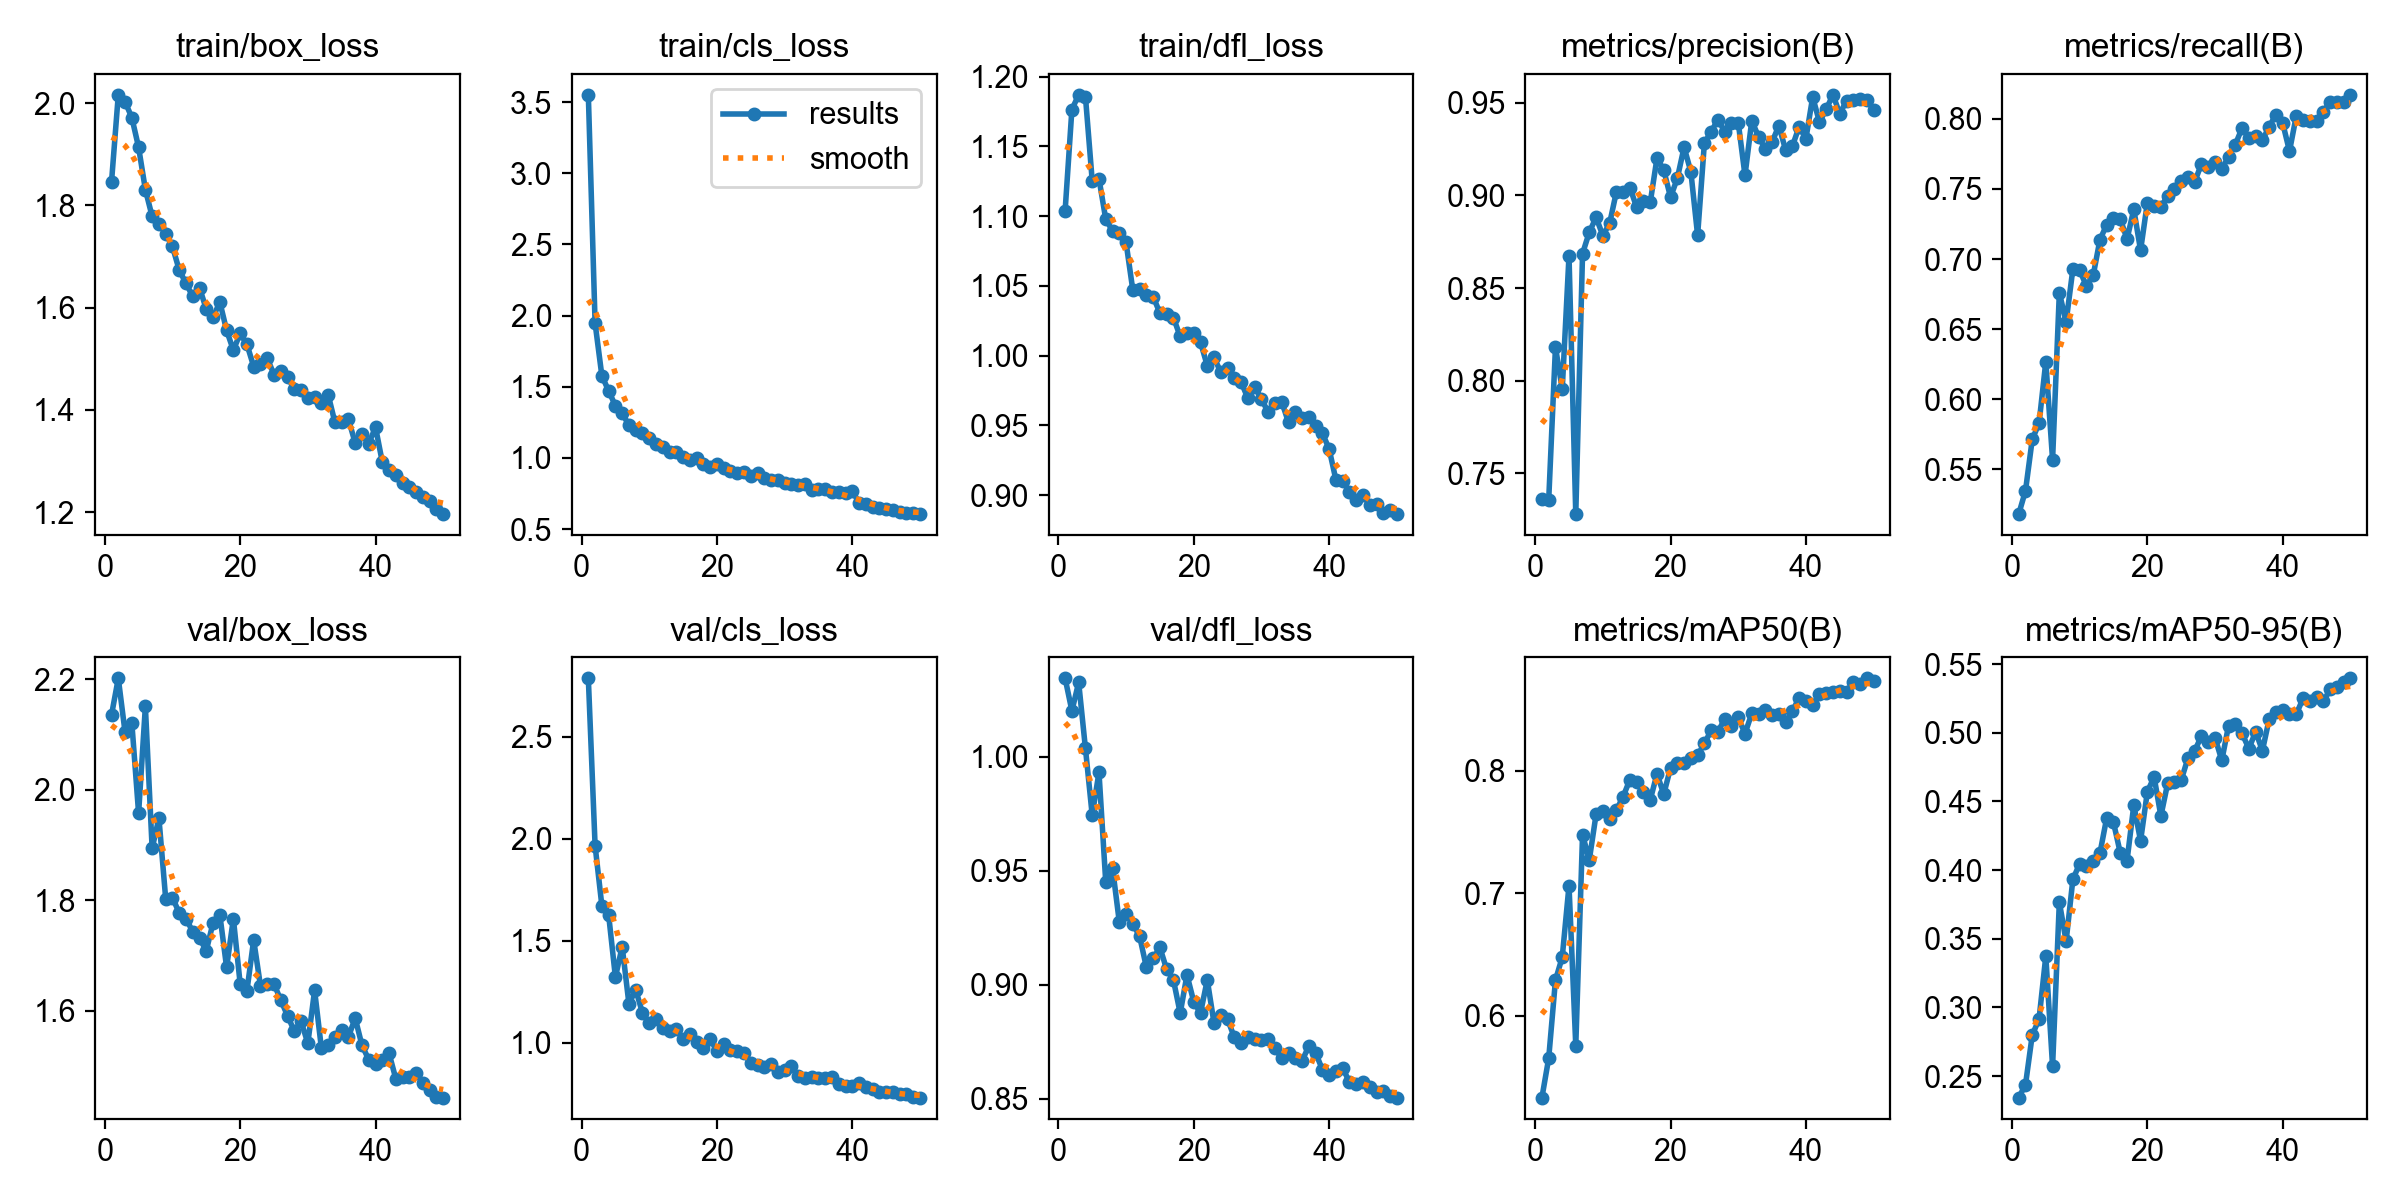

E3 confusion_matrix_normalized.png


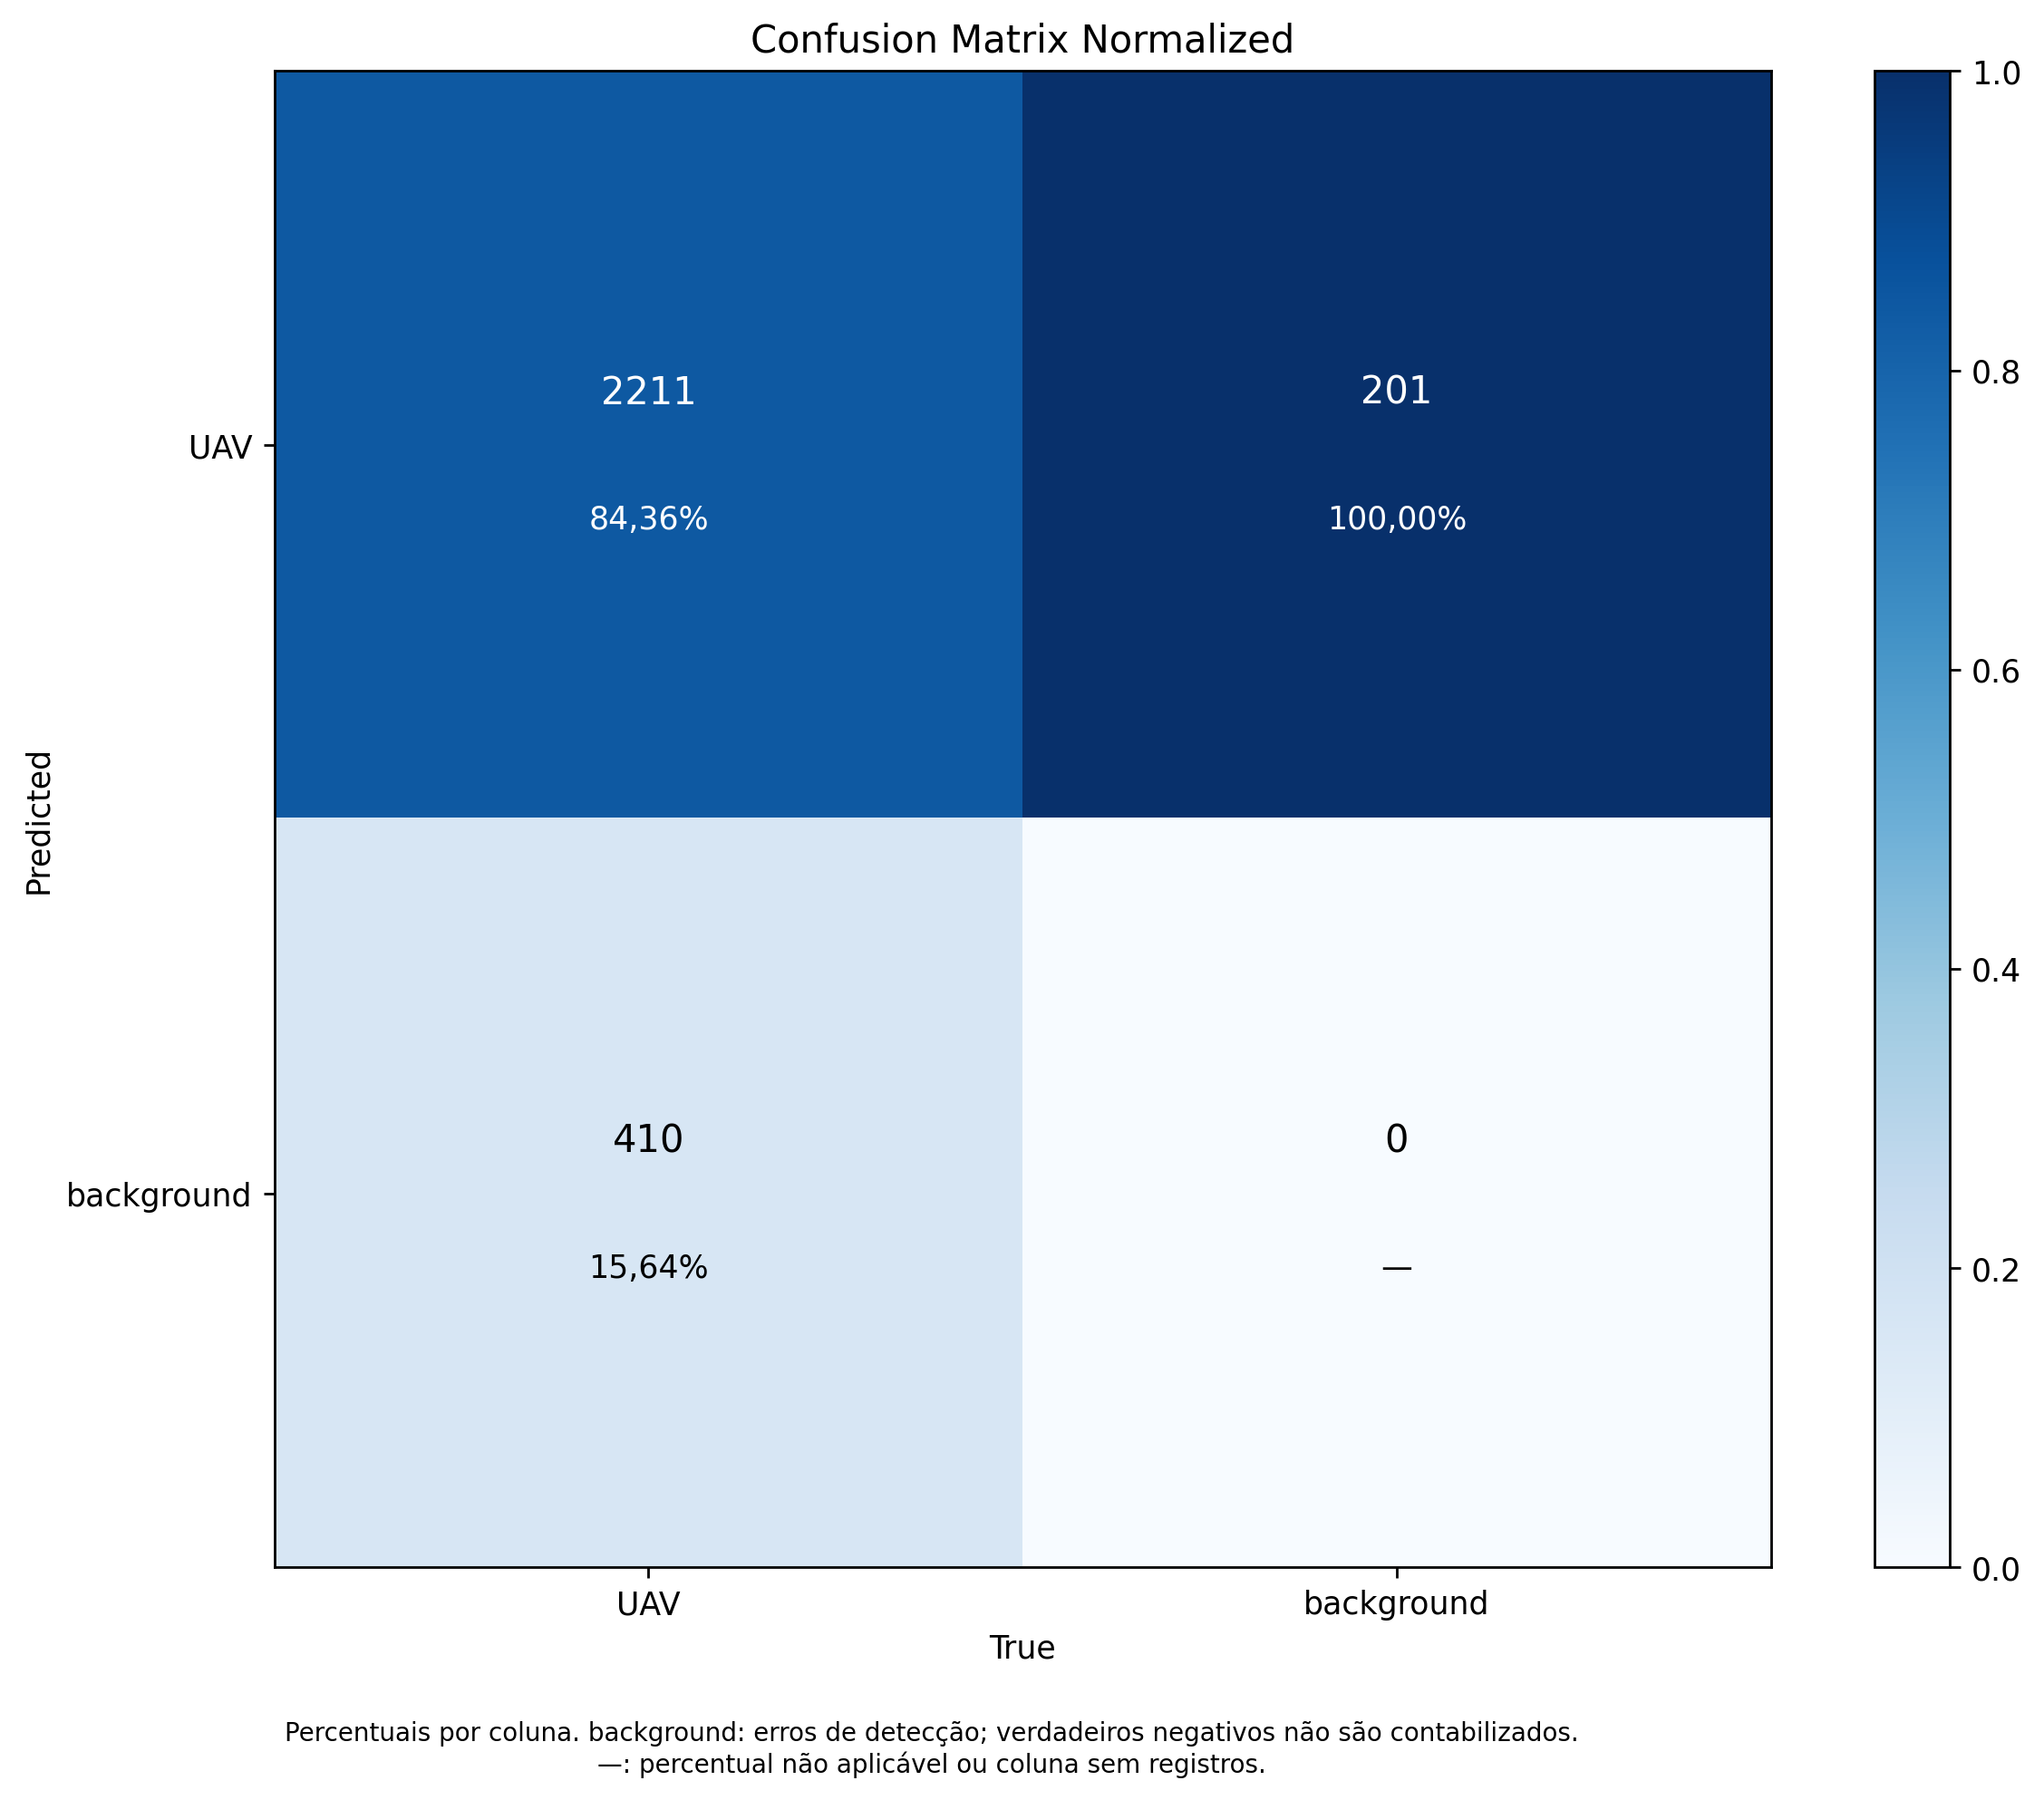

E3 BoxPR_curve.png


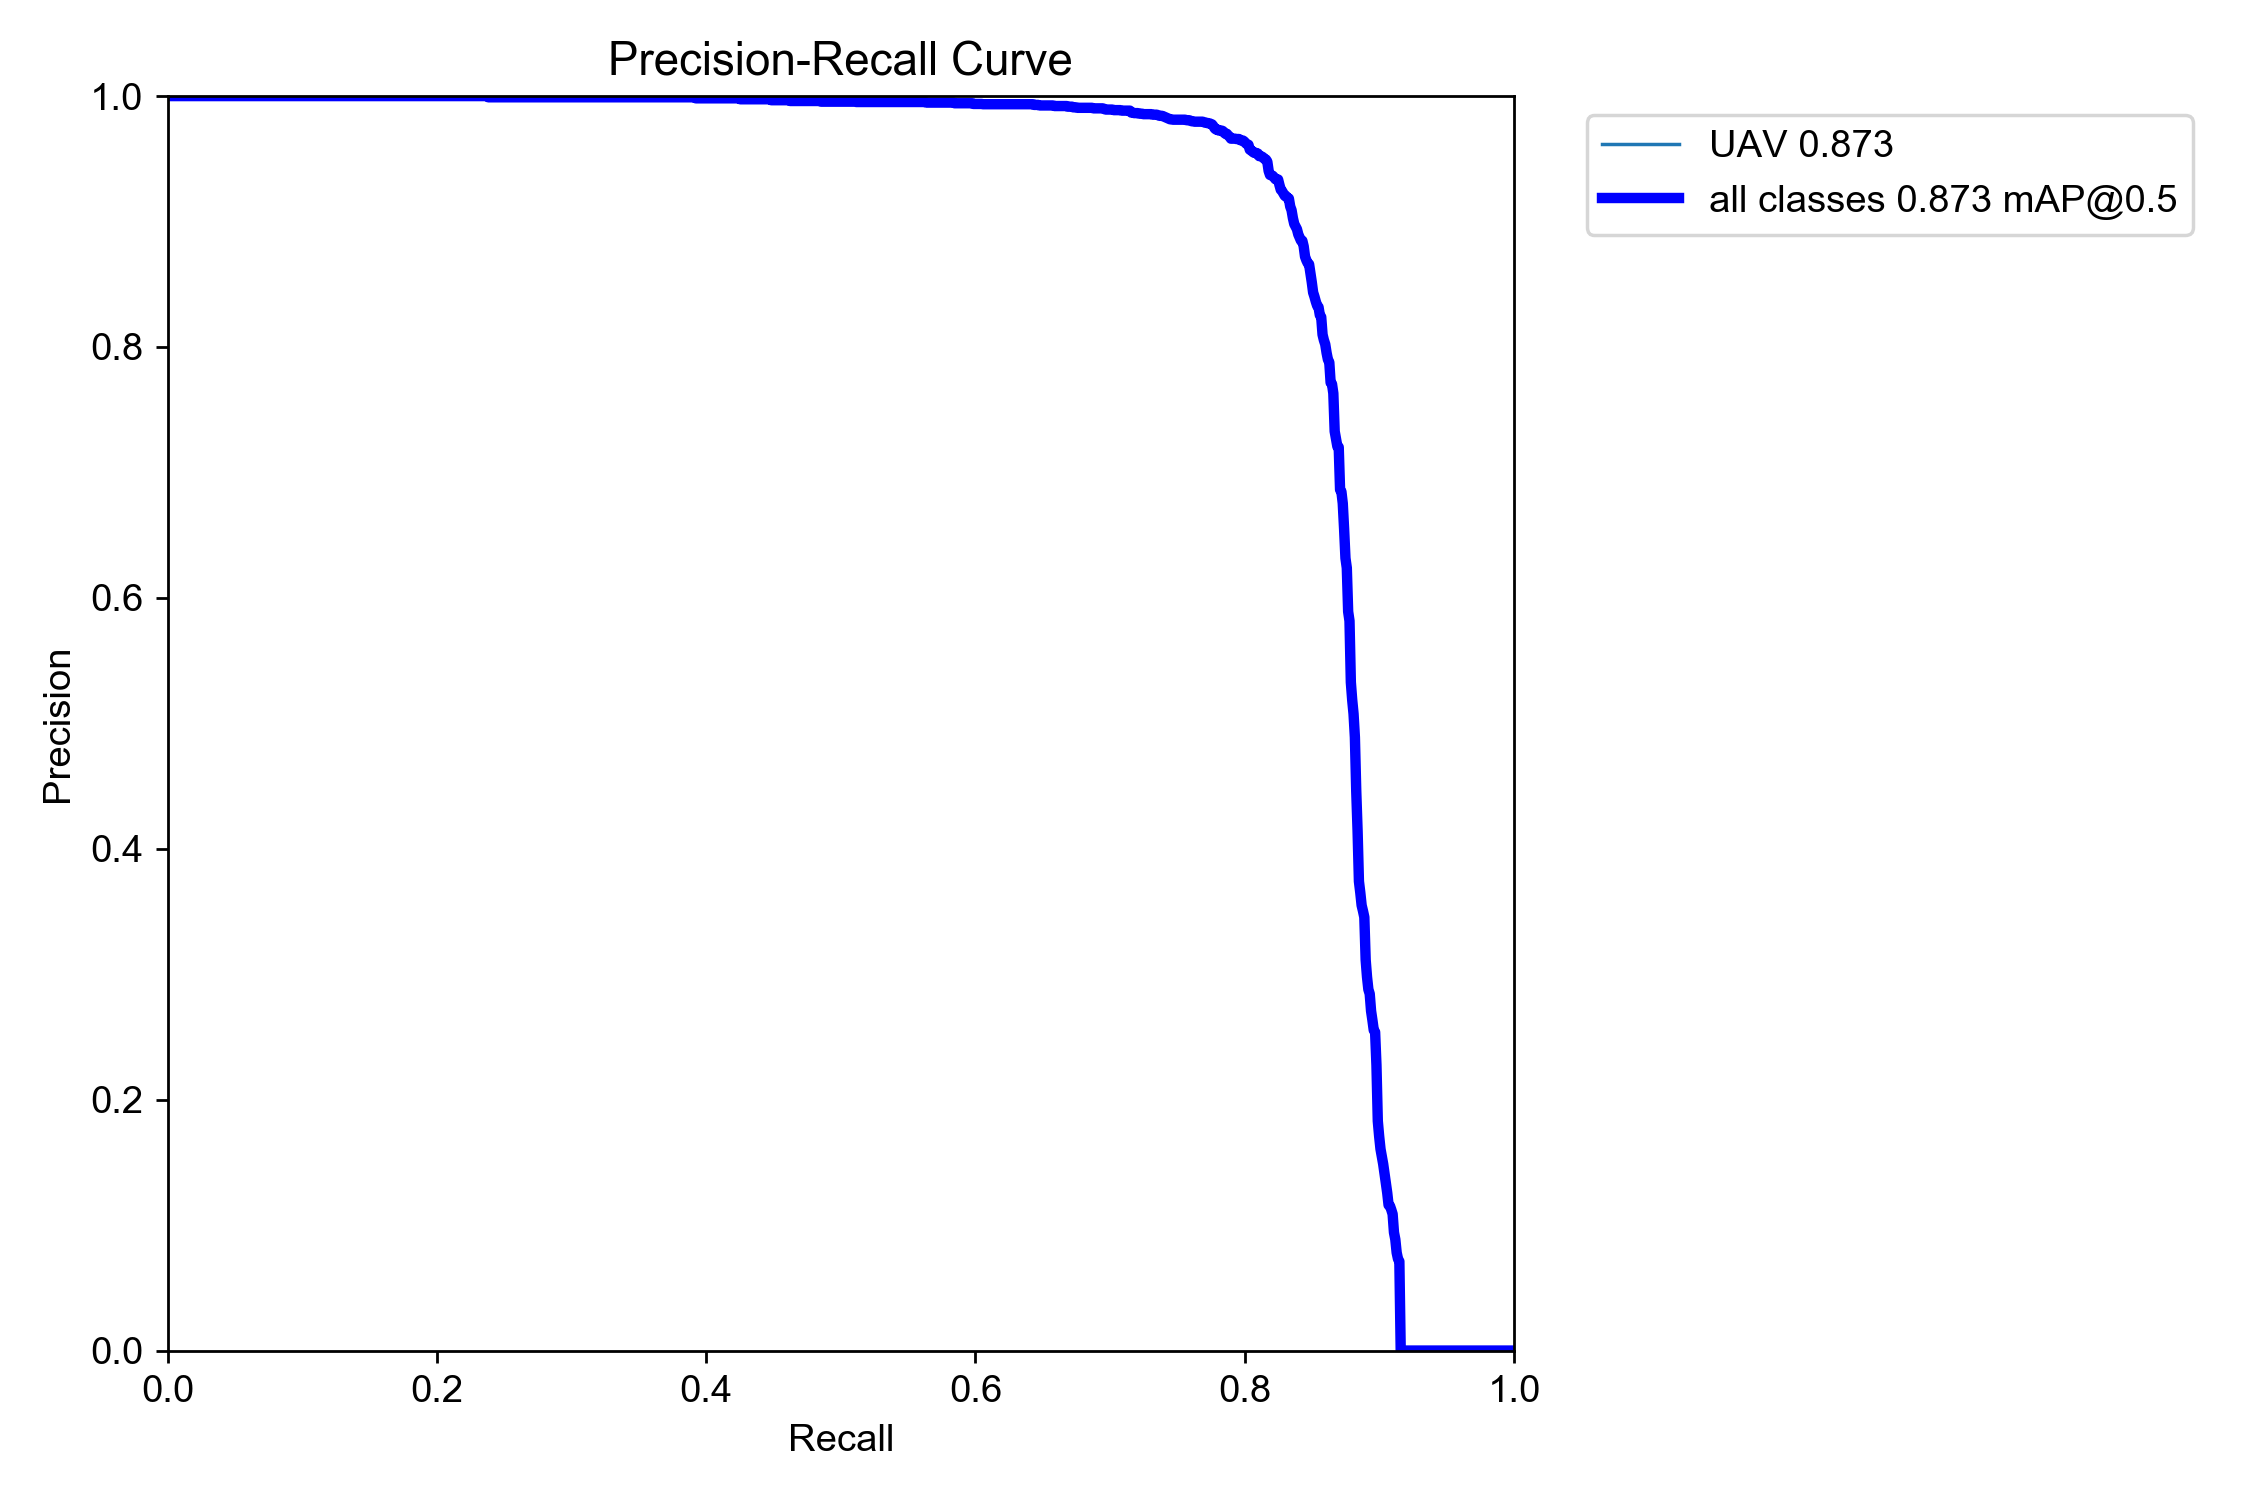

In [ ]:
historico=[]
for exp, folder in RUNS.items():
    df=pd.read_csv(ROOT/'runs/detect'/folder/'results.csv')
    df.columns=df.columns.str.strip()
    last=df.iloc[-1]
    historico.append({'Experimento':exp, 'Épocas':int(last['epoch']),
        'Precisão (val)':last['metrics/precision(B)'], 'Revocação (val)':last['metrics/recall(B)'],
        'mAP50 (val)':last['metrics/mAP50(B)'], 'mAP50–95 (val)':last['metrics/mAP50-95(B)'],
        'Tempo acumulado (h)':last['time']/3600})
historico=pd.DataFrame(historico)
display(historico)
historico.to_csv(LOCAL_OUTPUT/'historico_ultima_epoca_validacao.csv',index=False)
for name in ['results.png','confusion_matrix_normalized.png','BoxPR_curve.png']:
    print(EXPERIMENTO, name)
    if name == 'confusion_matrix_normalized.png':
        # Contagens transcritas das figuras originais de cada experimento.
        # Os arquivos históricos permanecem intactos; a nova figura fica em LOCAL_OUTPUT.
        matrizes_historicas = {
            'E1': [[1530, 931], [1091, 0]],
            'E2': [[2013, 202], [608, 0]],
            'E3': [[2211, 201], [410, 0]],
        }
        hashes_matrizes = {
            'E1': '6dcb0f7c6f8ffd7b406d71cb4fc6b5bb873d0918507d4e4d8923c1224ad66772',
            'E2': '6d962c6796a20d88322bdf1999df1f54040ef1ac90b190ba96fd4516443e04a3',
            'E3': 'c79f6deb03662ee25fad40c4fc89788fbc7901542f13eedd5624ea03a78af430',
        }
        matriz_original = ROOT/'runs/detect'/RUNS[EXPERIMENTO]/'confusion_matrix.png'
        assert sha256_file(matriz_original) == hashes_matrizes[EXPERIMENTO], 'A figura histórica difere daquela conferida.'
        fig_cm = figura_matriz_deteccao(matrizes_historicas[EXPERIMENTO], normalizada=True)
        caminho_cm = LOCAL_OUTPUT/f'confusion_matrix_{EXPERIMENTO}_percentuais.png'
        fig_cm.savefig(caminho_cm, dpi=250, bbox_inches='tight')
        import matplotlib.pyplot as plt
        plt.close(fig_cm)
        display(Image(filename=str(caminho_cm), width=750))
    else:
        display(Image(filename=str(ROOT/'runs/detect'/RUNS[EXPERIMENTO]/name),width=750))


## 6. Avaliar o conjunto anotado — opcional

Esta etapa calcula métricas em todas as imagens de uma divisão do DUT Anti-UAV, sem treinar o modelo novamente.

1. Altere `EXECUTAR_AVALIACAO` para `True`.
2. Leia as limitações dos dados apresentadas no início e altere `CIENTE_DAS_LIMITACOES` para `True`. Essa opção registra a ciência das limitações; não corrige os dados.
3. Escolha `SPLIT = 'val'` para validação ou `SPLIT = 'test'` para o teste final.
4. Execute a célula e aguarde a tabela de métricas e os gráficos. Em CPU, o processo pode levar vários minutos.

Utilize a validação para comparar configurações e reserve o teste para avaliar o modelo após fixar o protocolo. Não escolha o modelo pelo desempenho no teste.

A saída apresenta precisão, revocação, mAP@50 e mAP@50–95. O filtro `conf=0.001` permite construir as curvas de avaliação; não é o mesmo limiar da demonstração de imagens. `iou=0.7` controla a supressão de caixas (NMS), não os limiares de IoU das métricas mAP. Os resumos de precisão/revocação e a matriz de confusão podem representar pontos de operação diferentes.

**A imagem duplicada entre treino e teste limita a independência da avaliação.** Essa ressalva deve acompanhar a apresentação dos resultados.

Ultralytics 8.4.53 🚀 Python-3.13.15 torch-2.11.0+cpu CPU (Intel Xeon CPU @ 2.20GHz)
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1506.0±564.3 MB/s, size: 132.0 KB)
val: Scanning /content/tcc_deteccao_f18aeb70/DUT_Anti_UAV/test/labels... 2200 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 2200/2200 1.7Kit/s 1.3s
val: New cache created: /content/tcc_deteccao_f18aeb70/DUT_Anti_UAV/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 138/138 3.1s/it 7:10
                   all       2200       2245      0.942      0.885      0.927      0.611
Speed: 2.7ms preprocess, 178.8ms inference, 0.0ms loss, 0.4ms postprocess per image
Results saved to /content/tcc_deteccao_f18aeb70/resultados/20260923T140059Z_0a282efd/avaliacao_E3_test


,metrics/precision(B),metrics/recall(B),metrics/mAP50(B),metrics/mAP50-95(B),fitness
0,0.941809,0.885078,0.927318,0.611091,0.611091


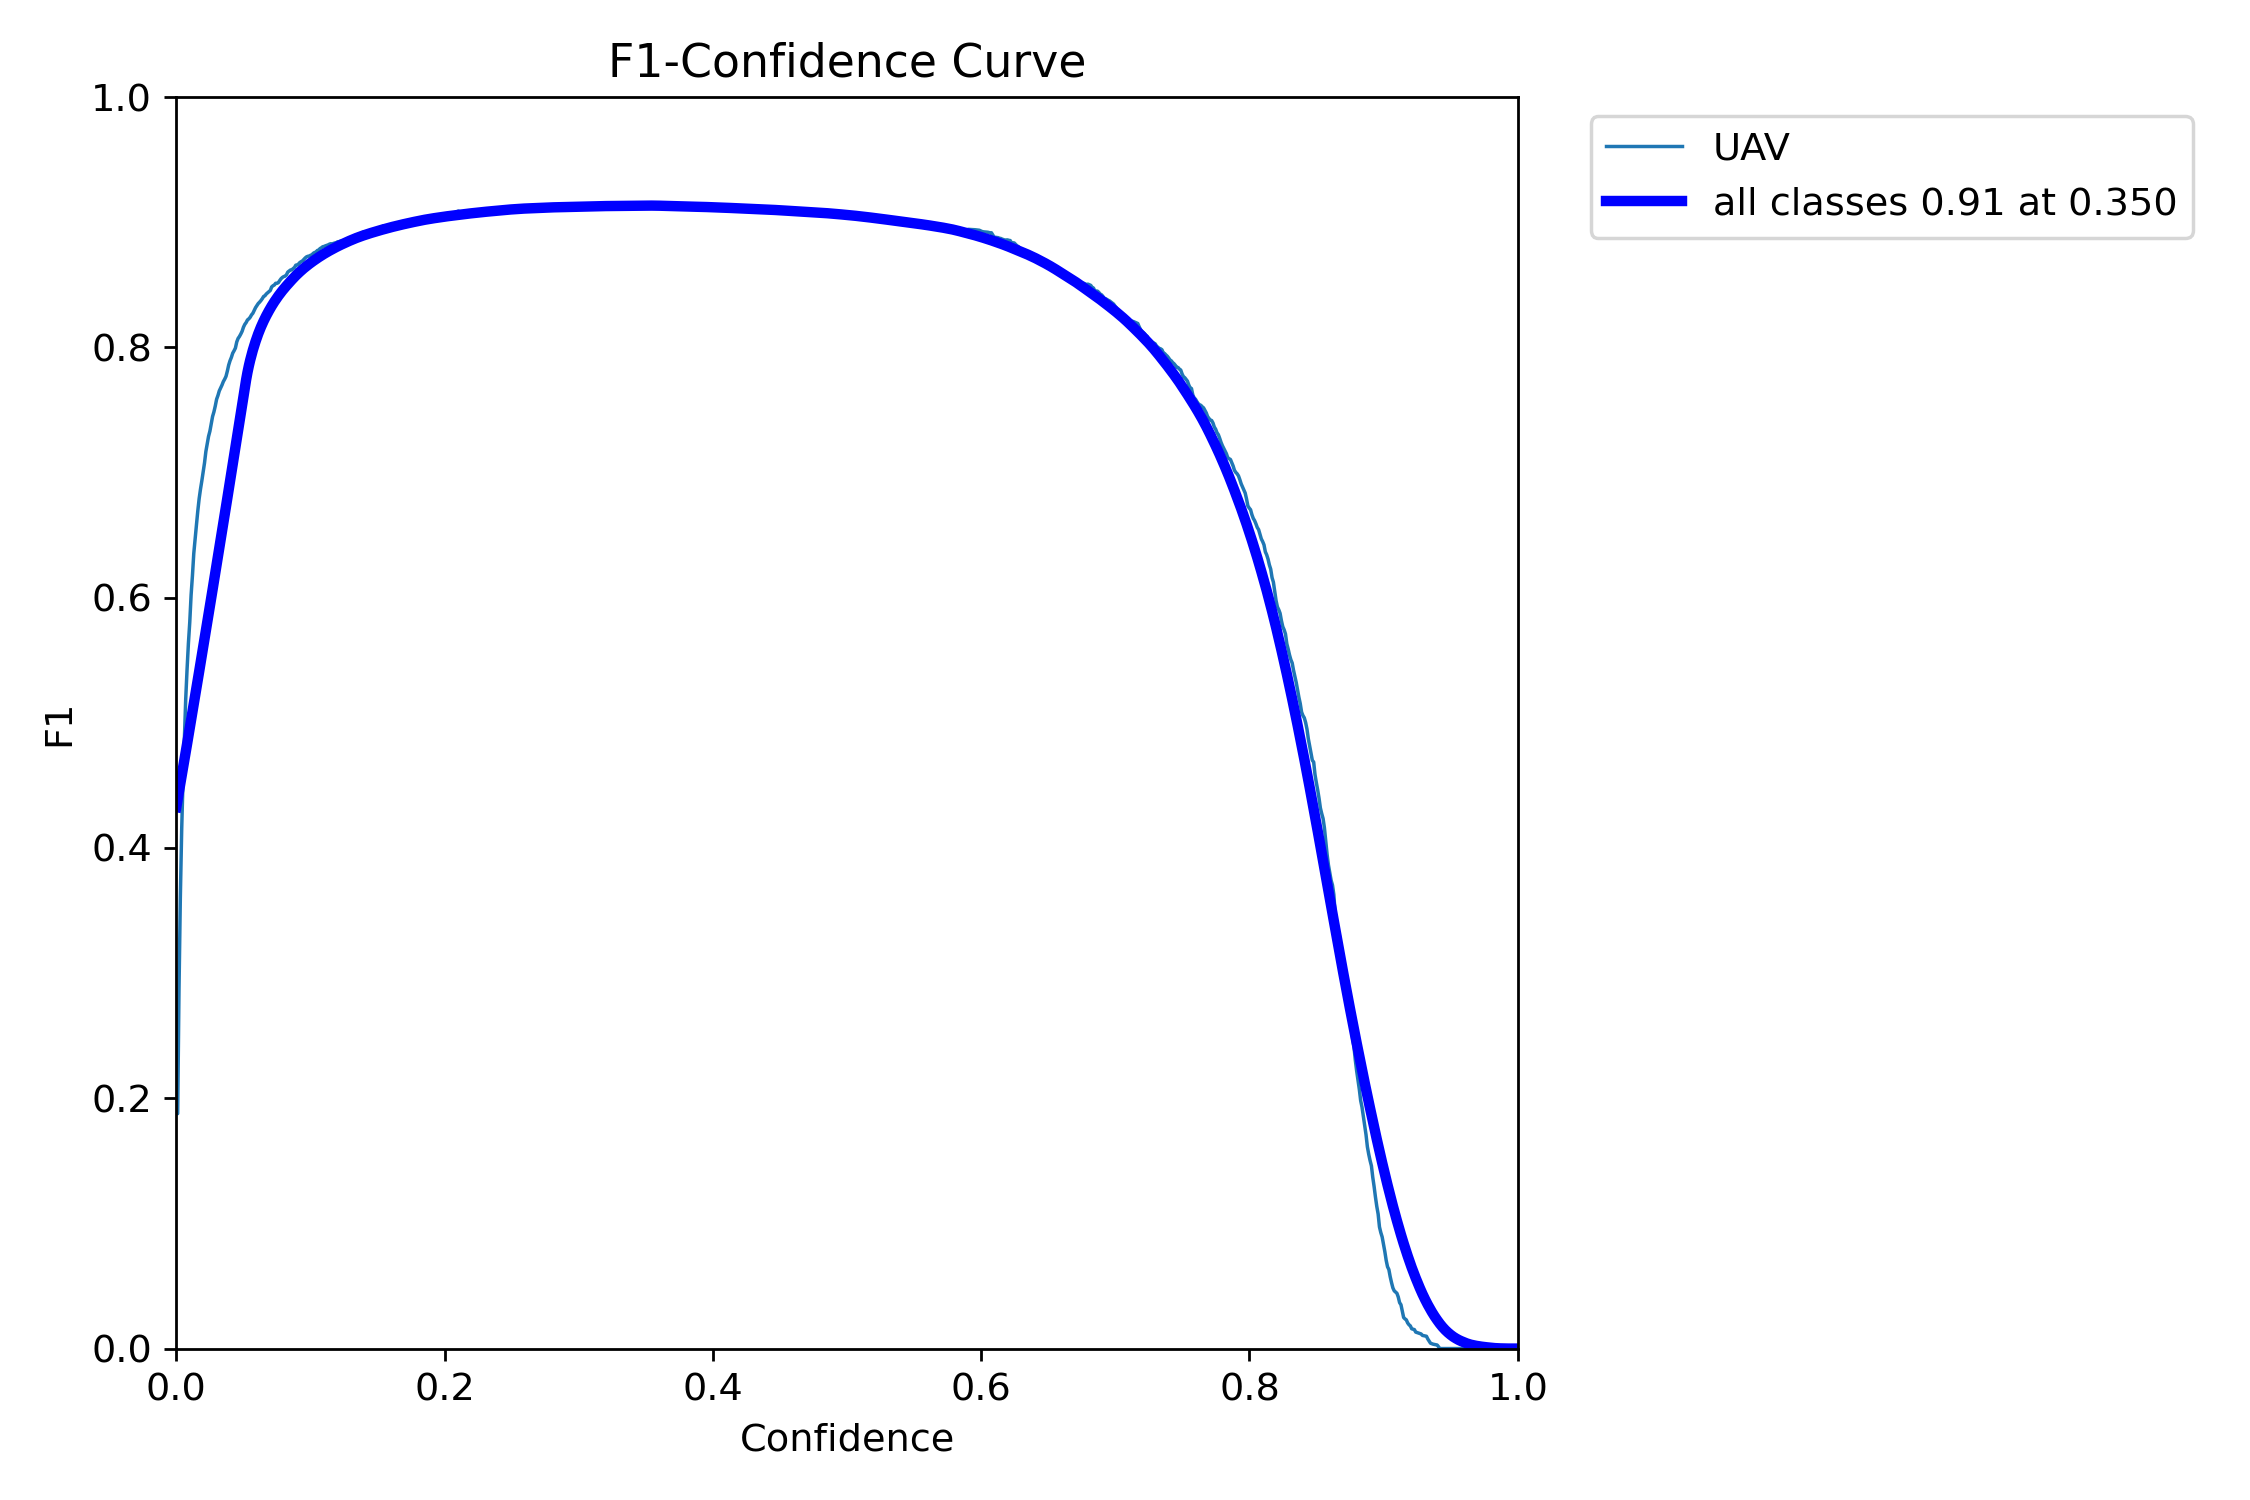

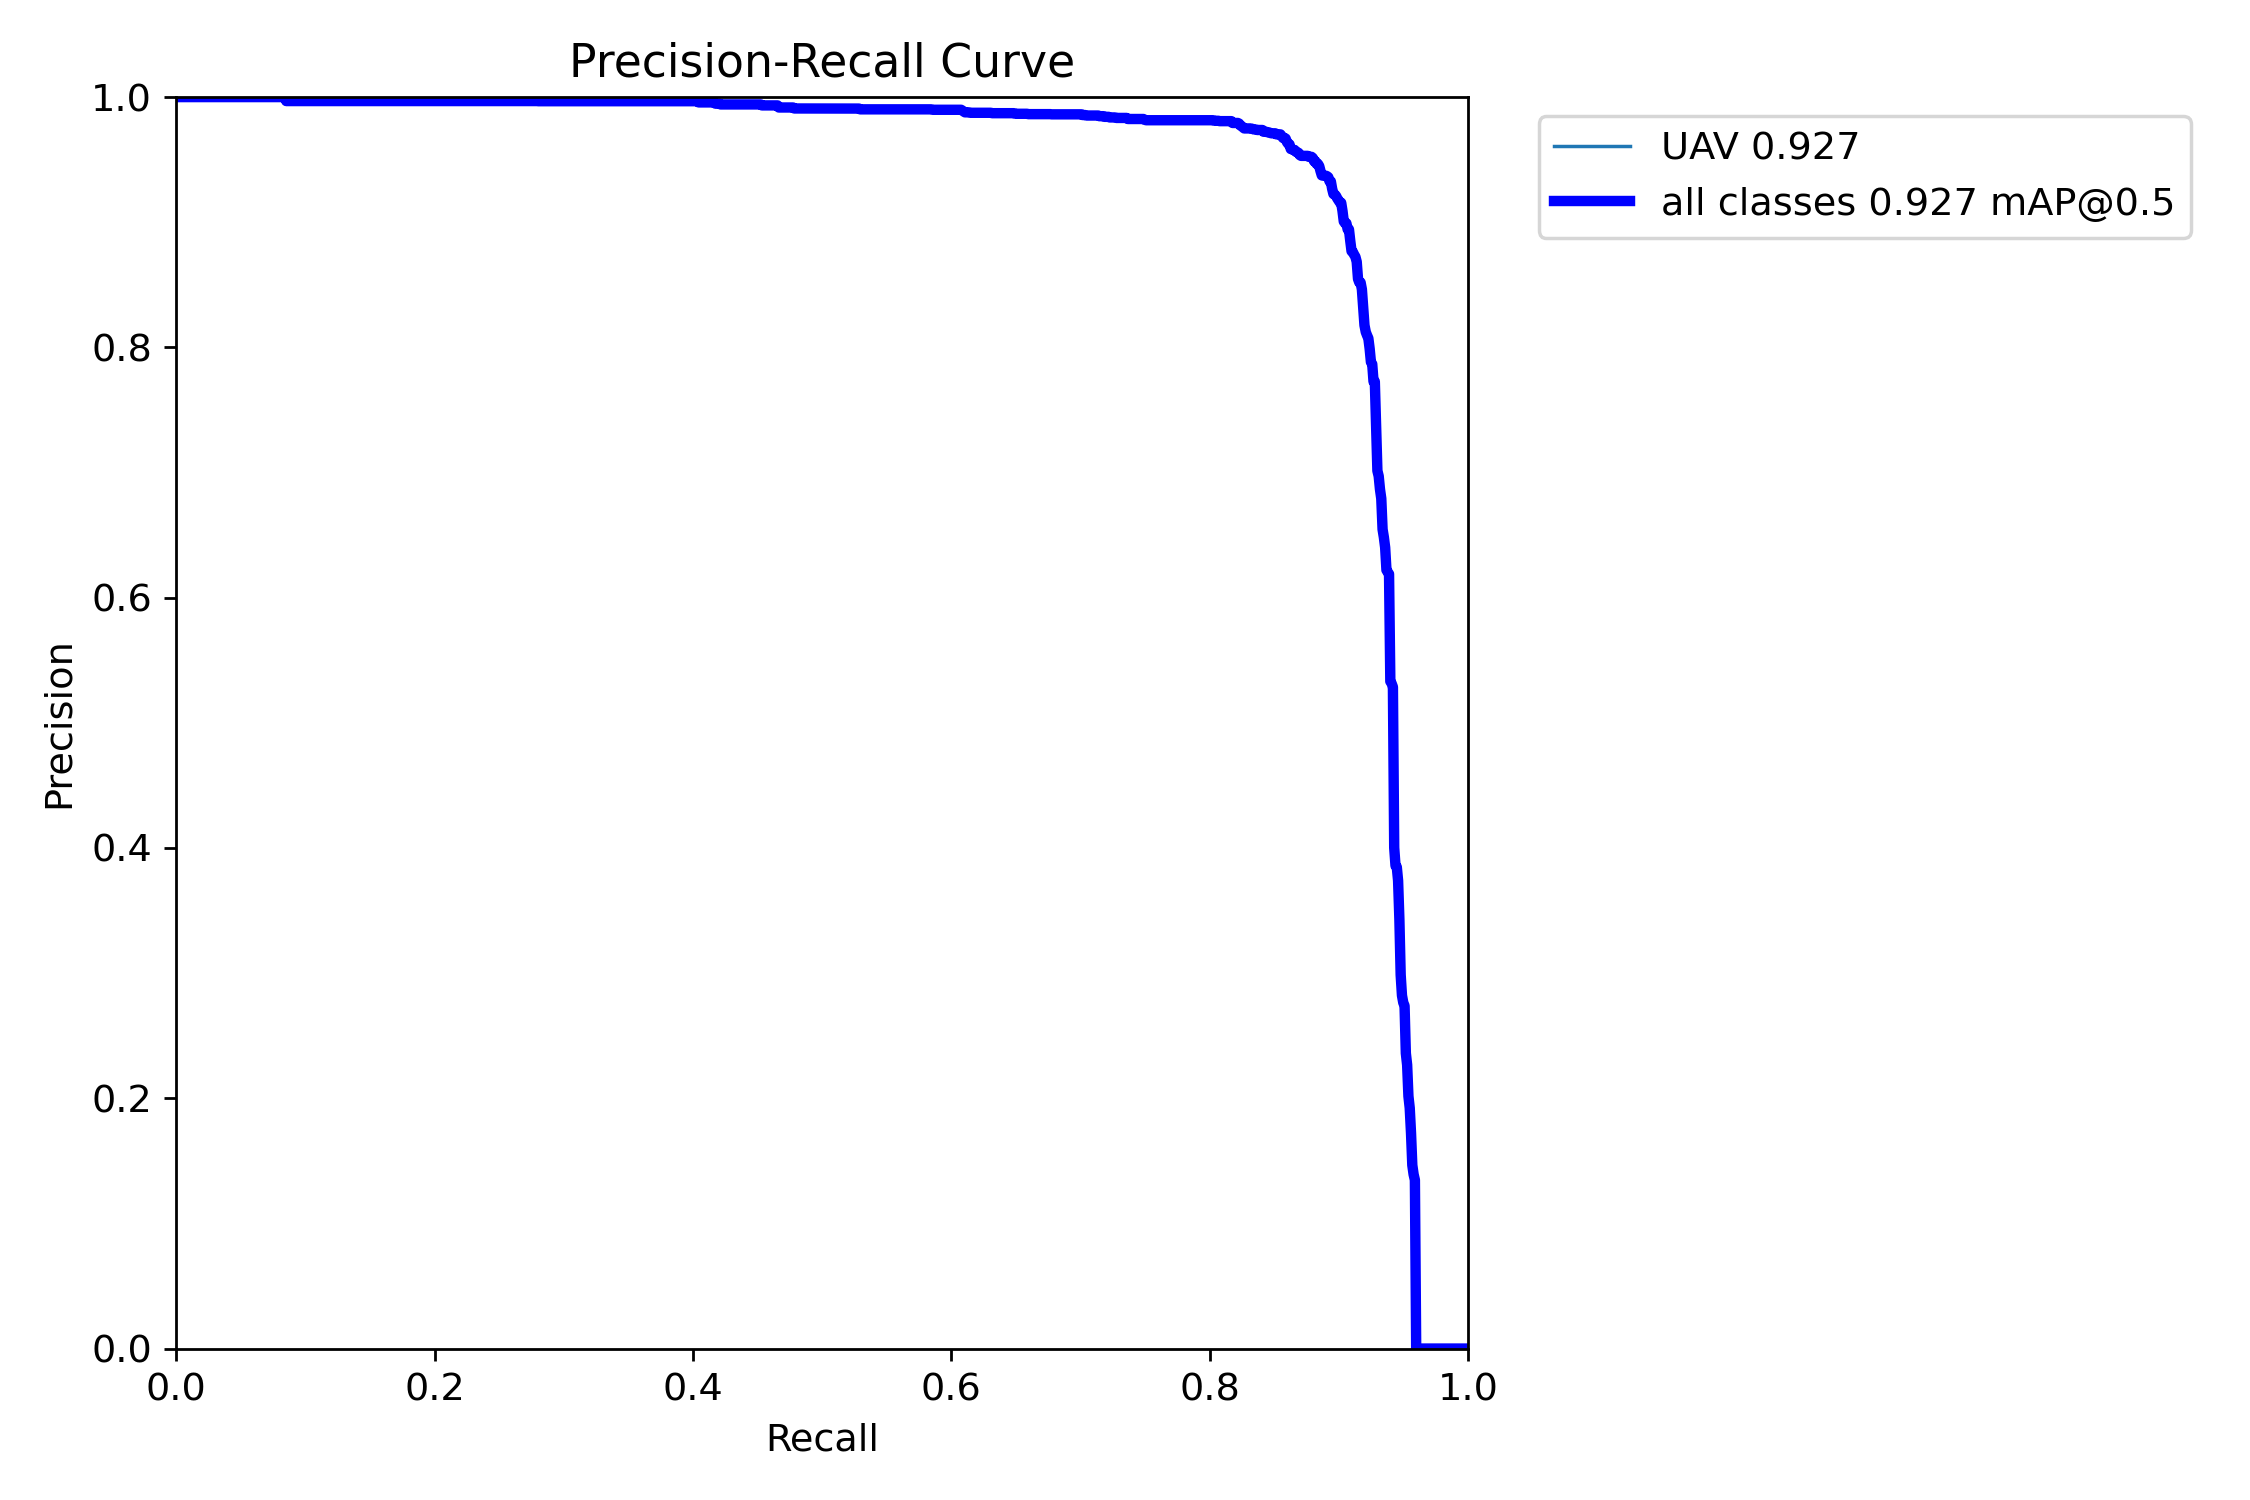

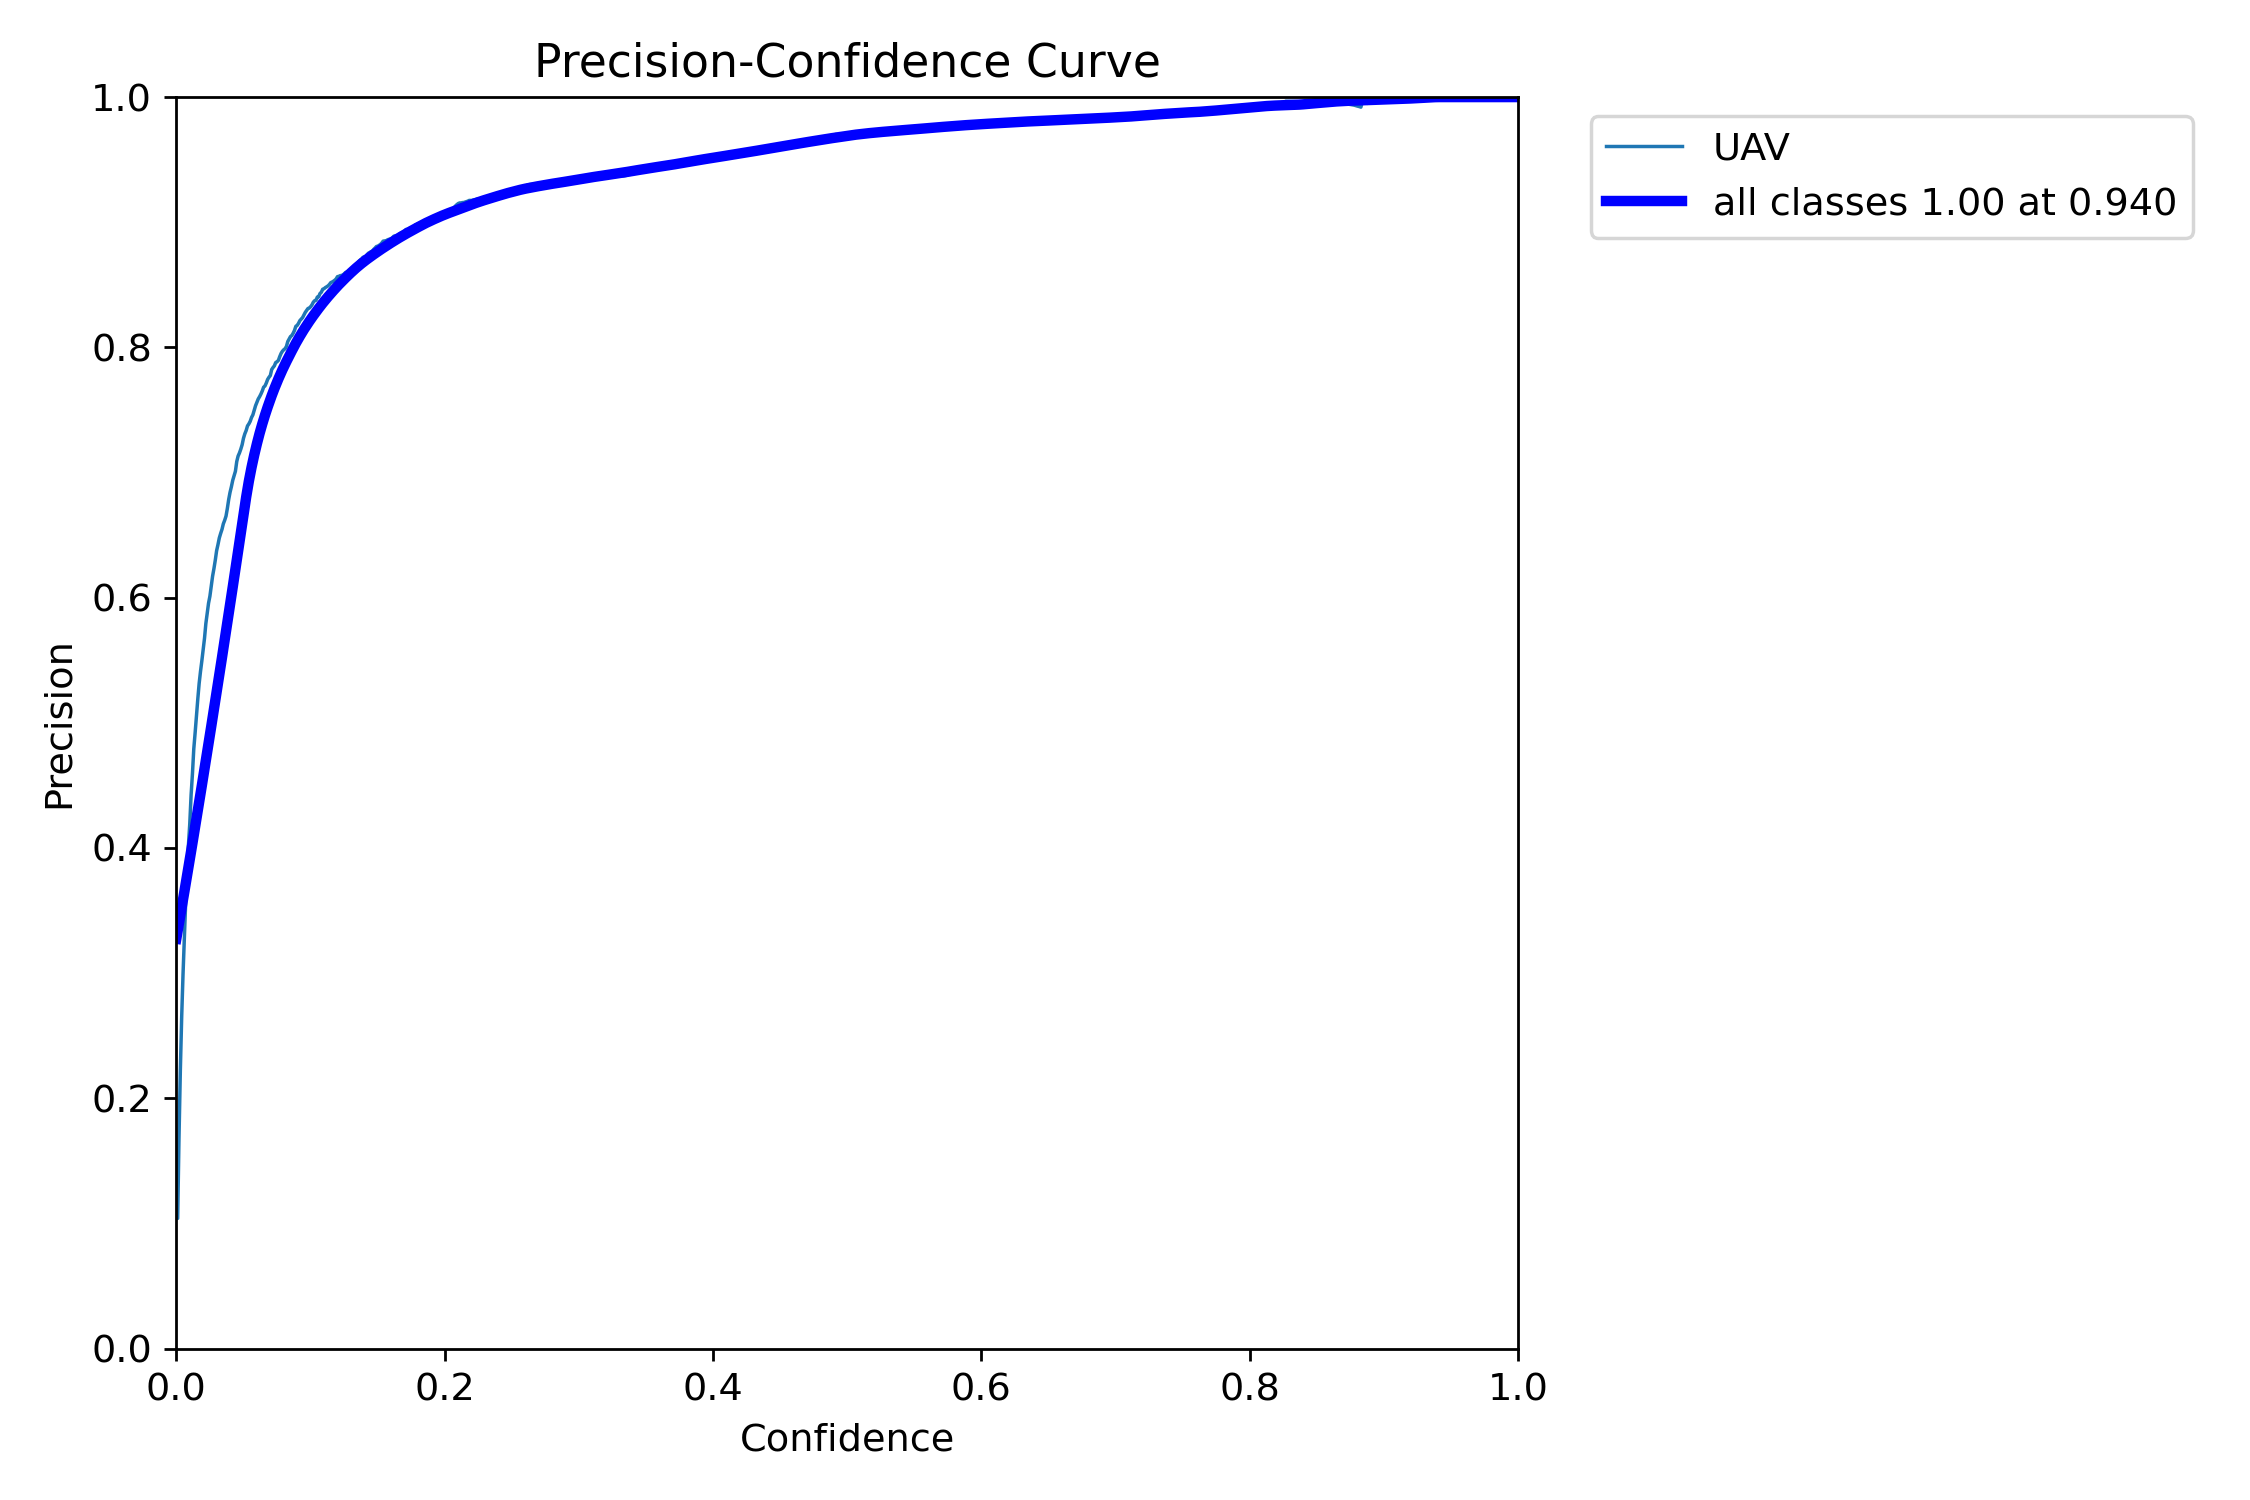

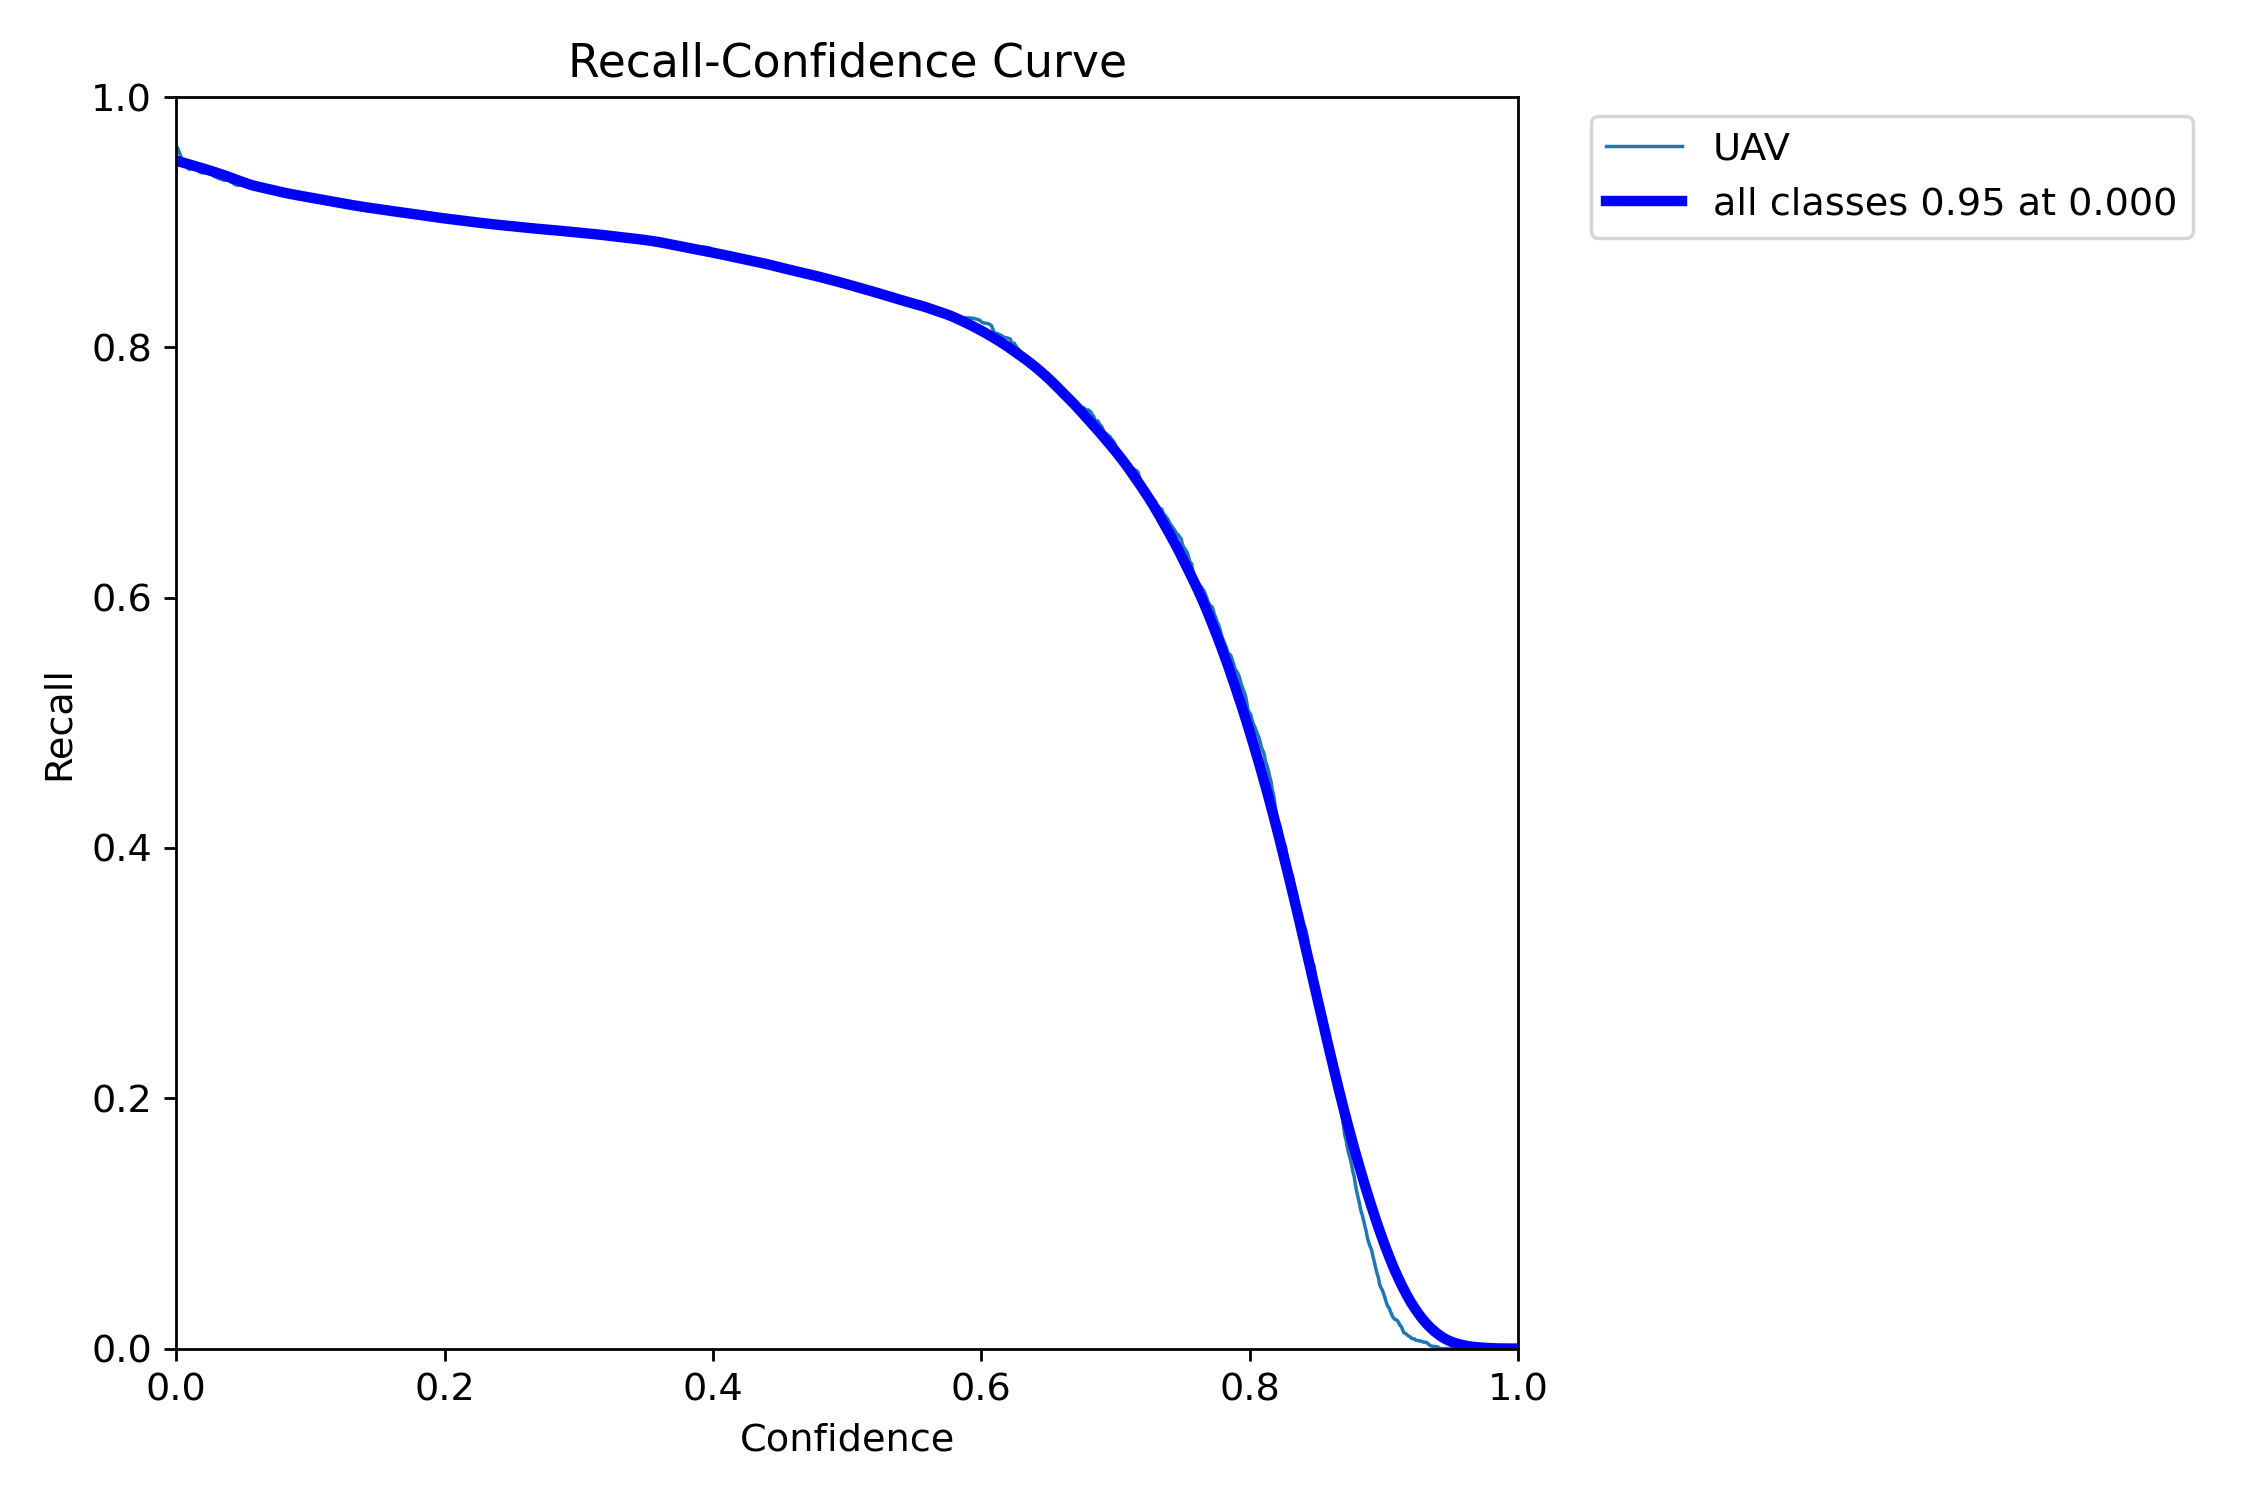

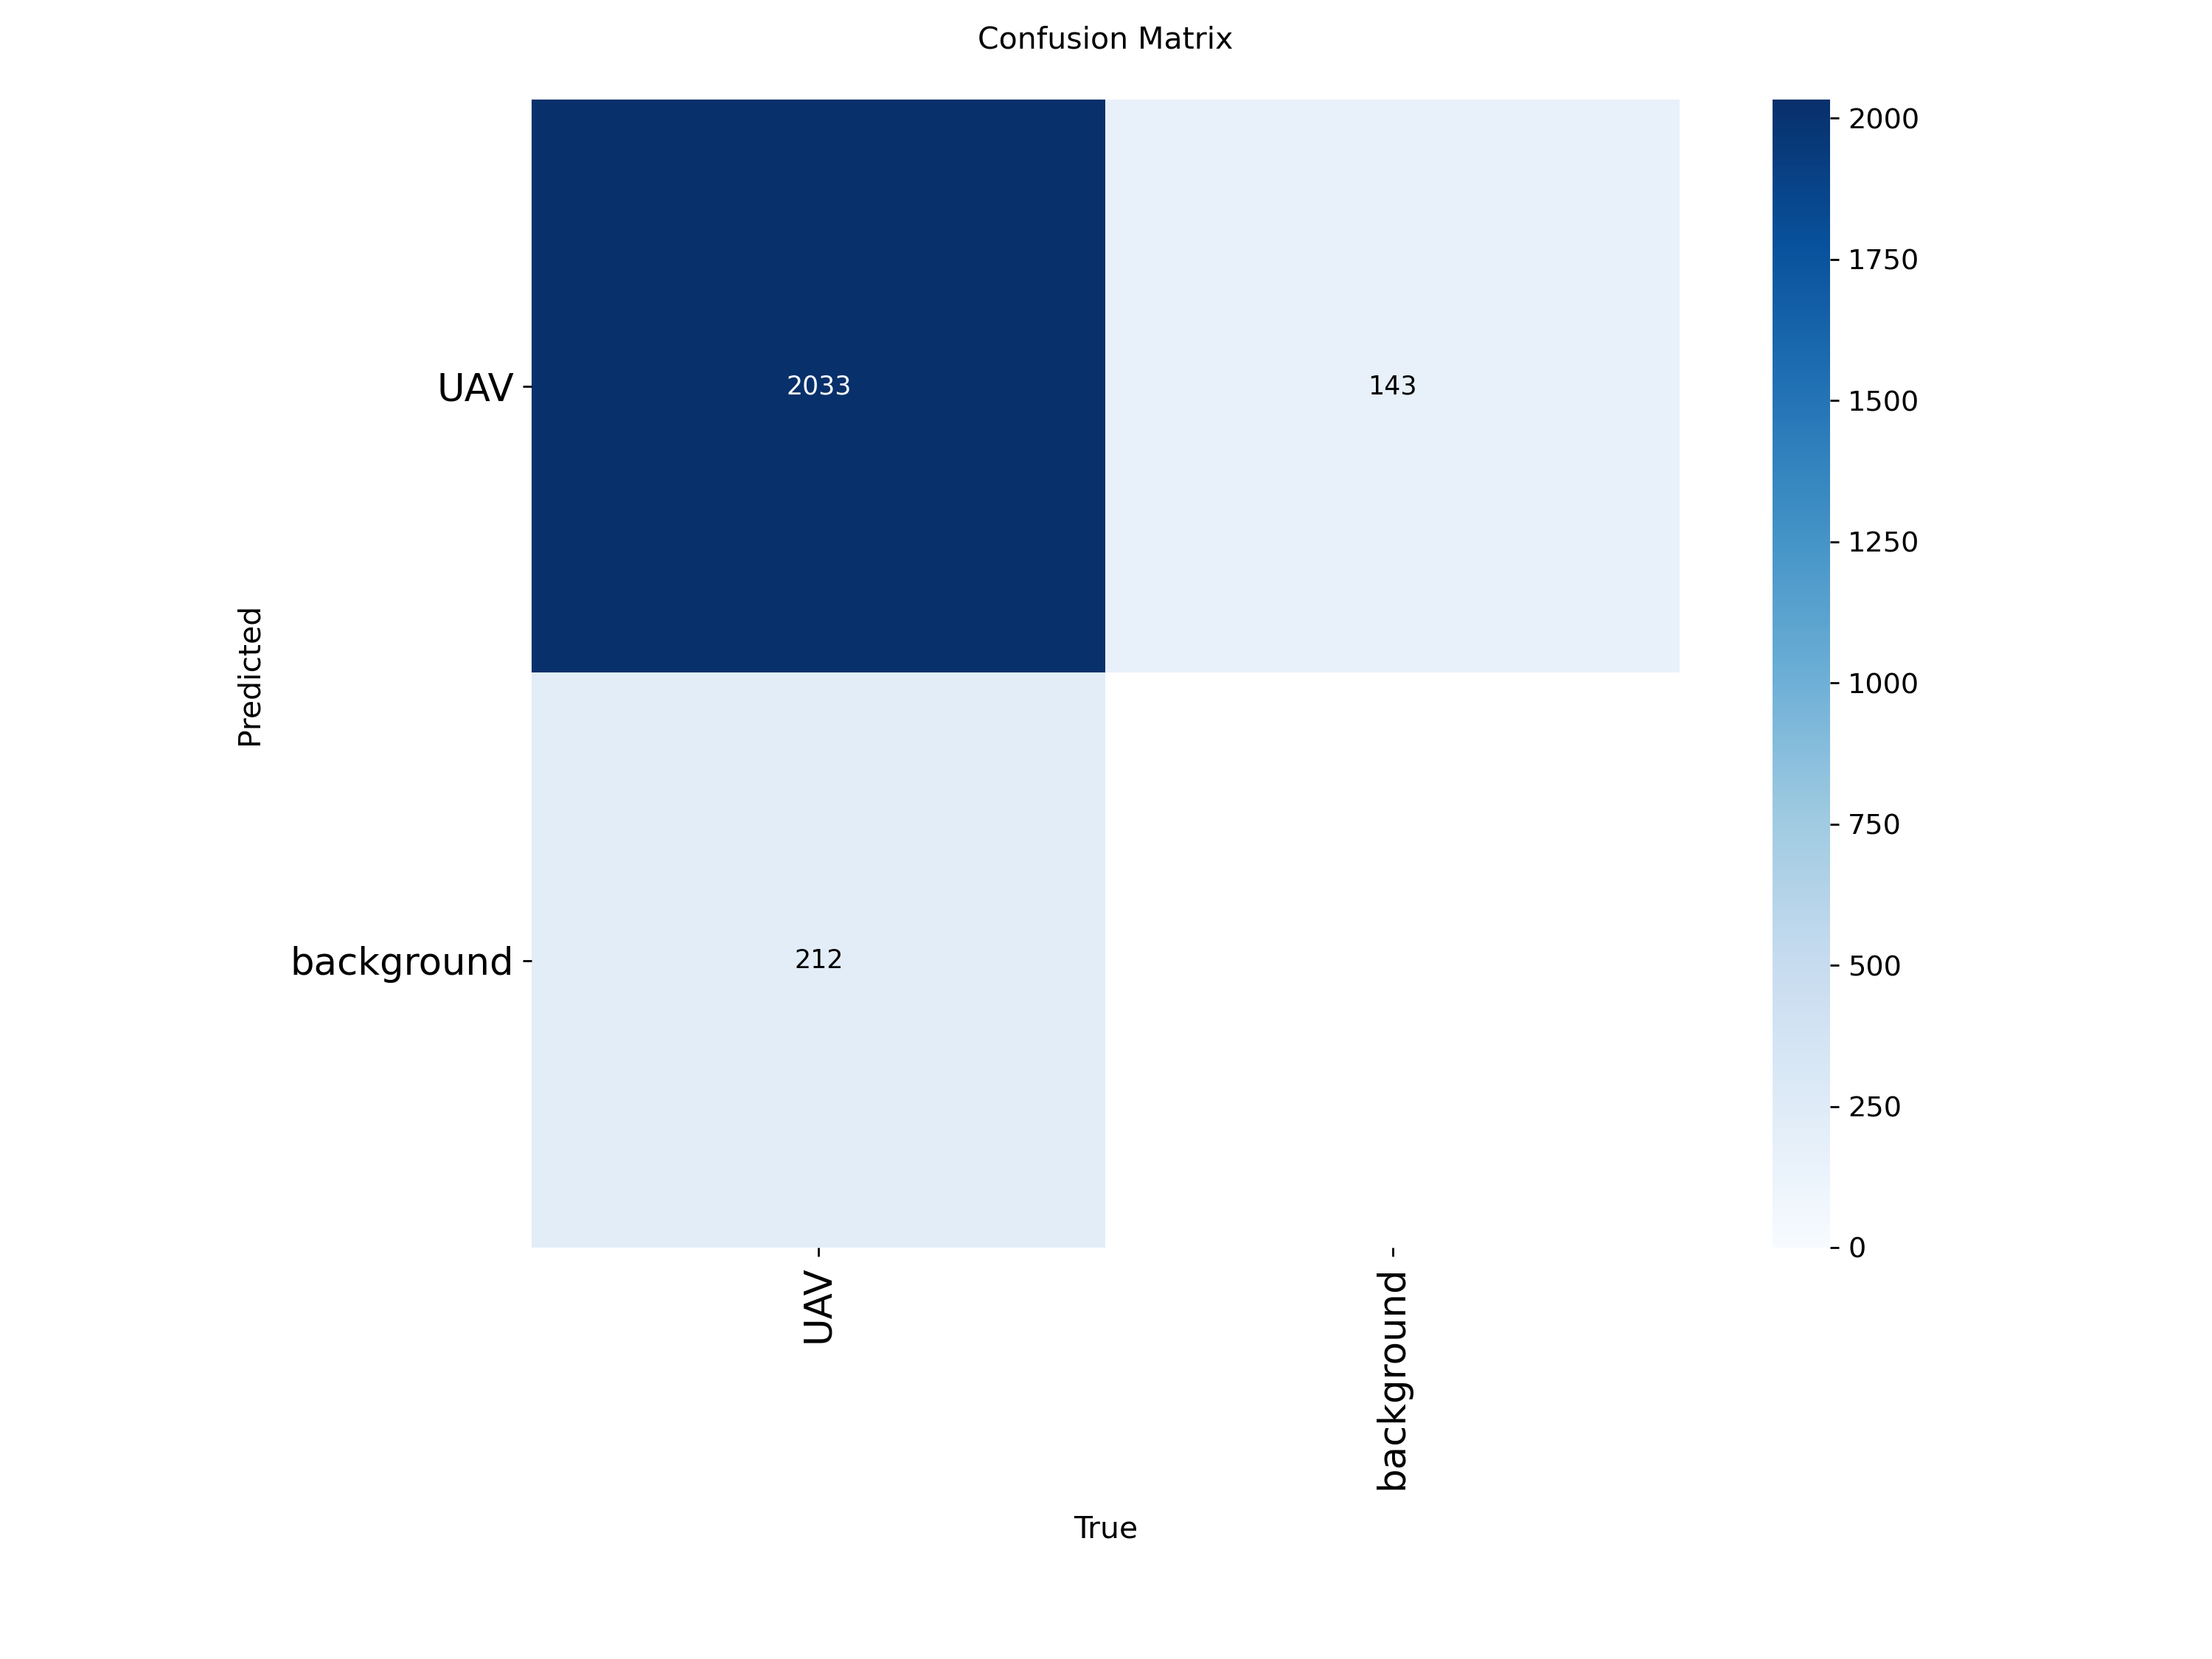

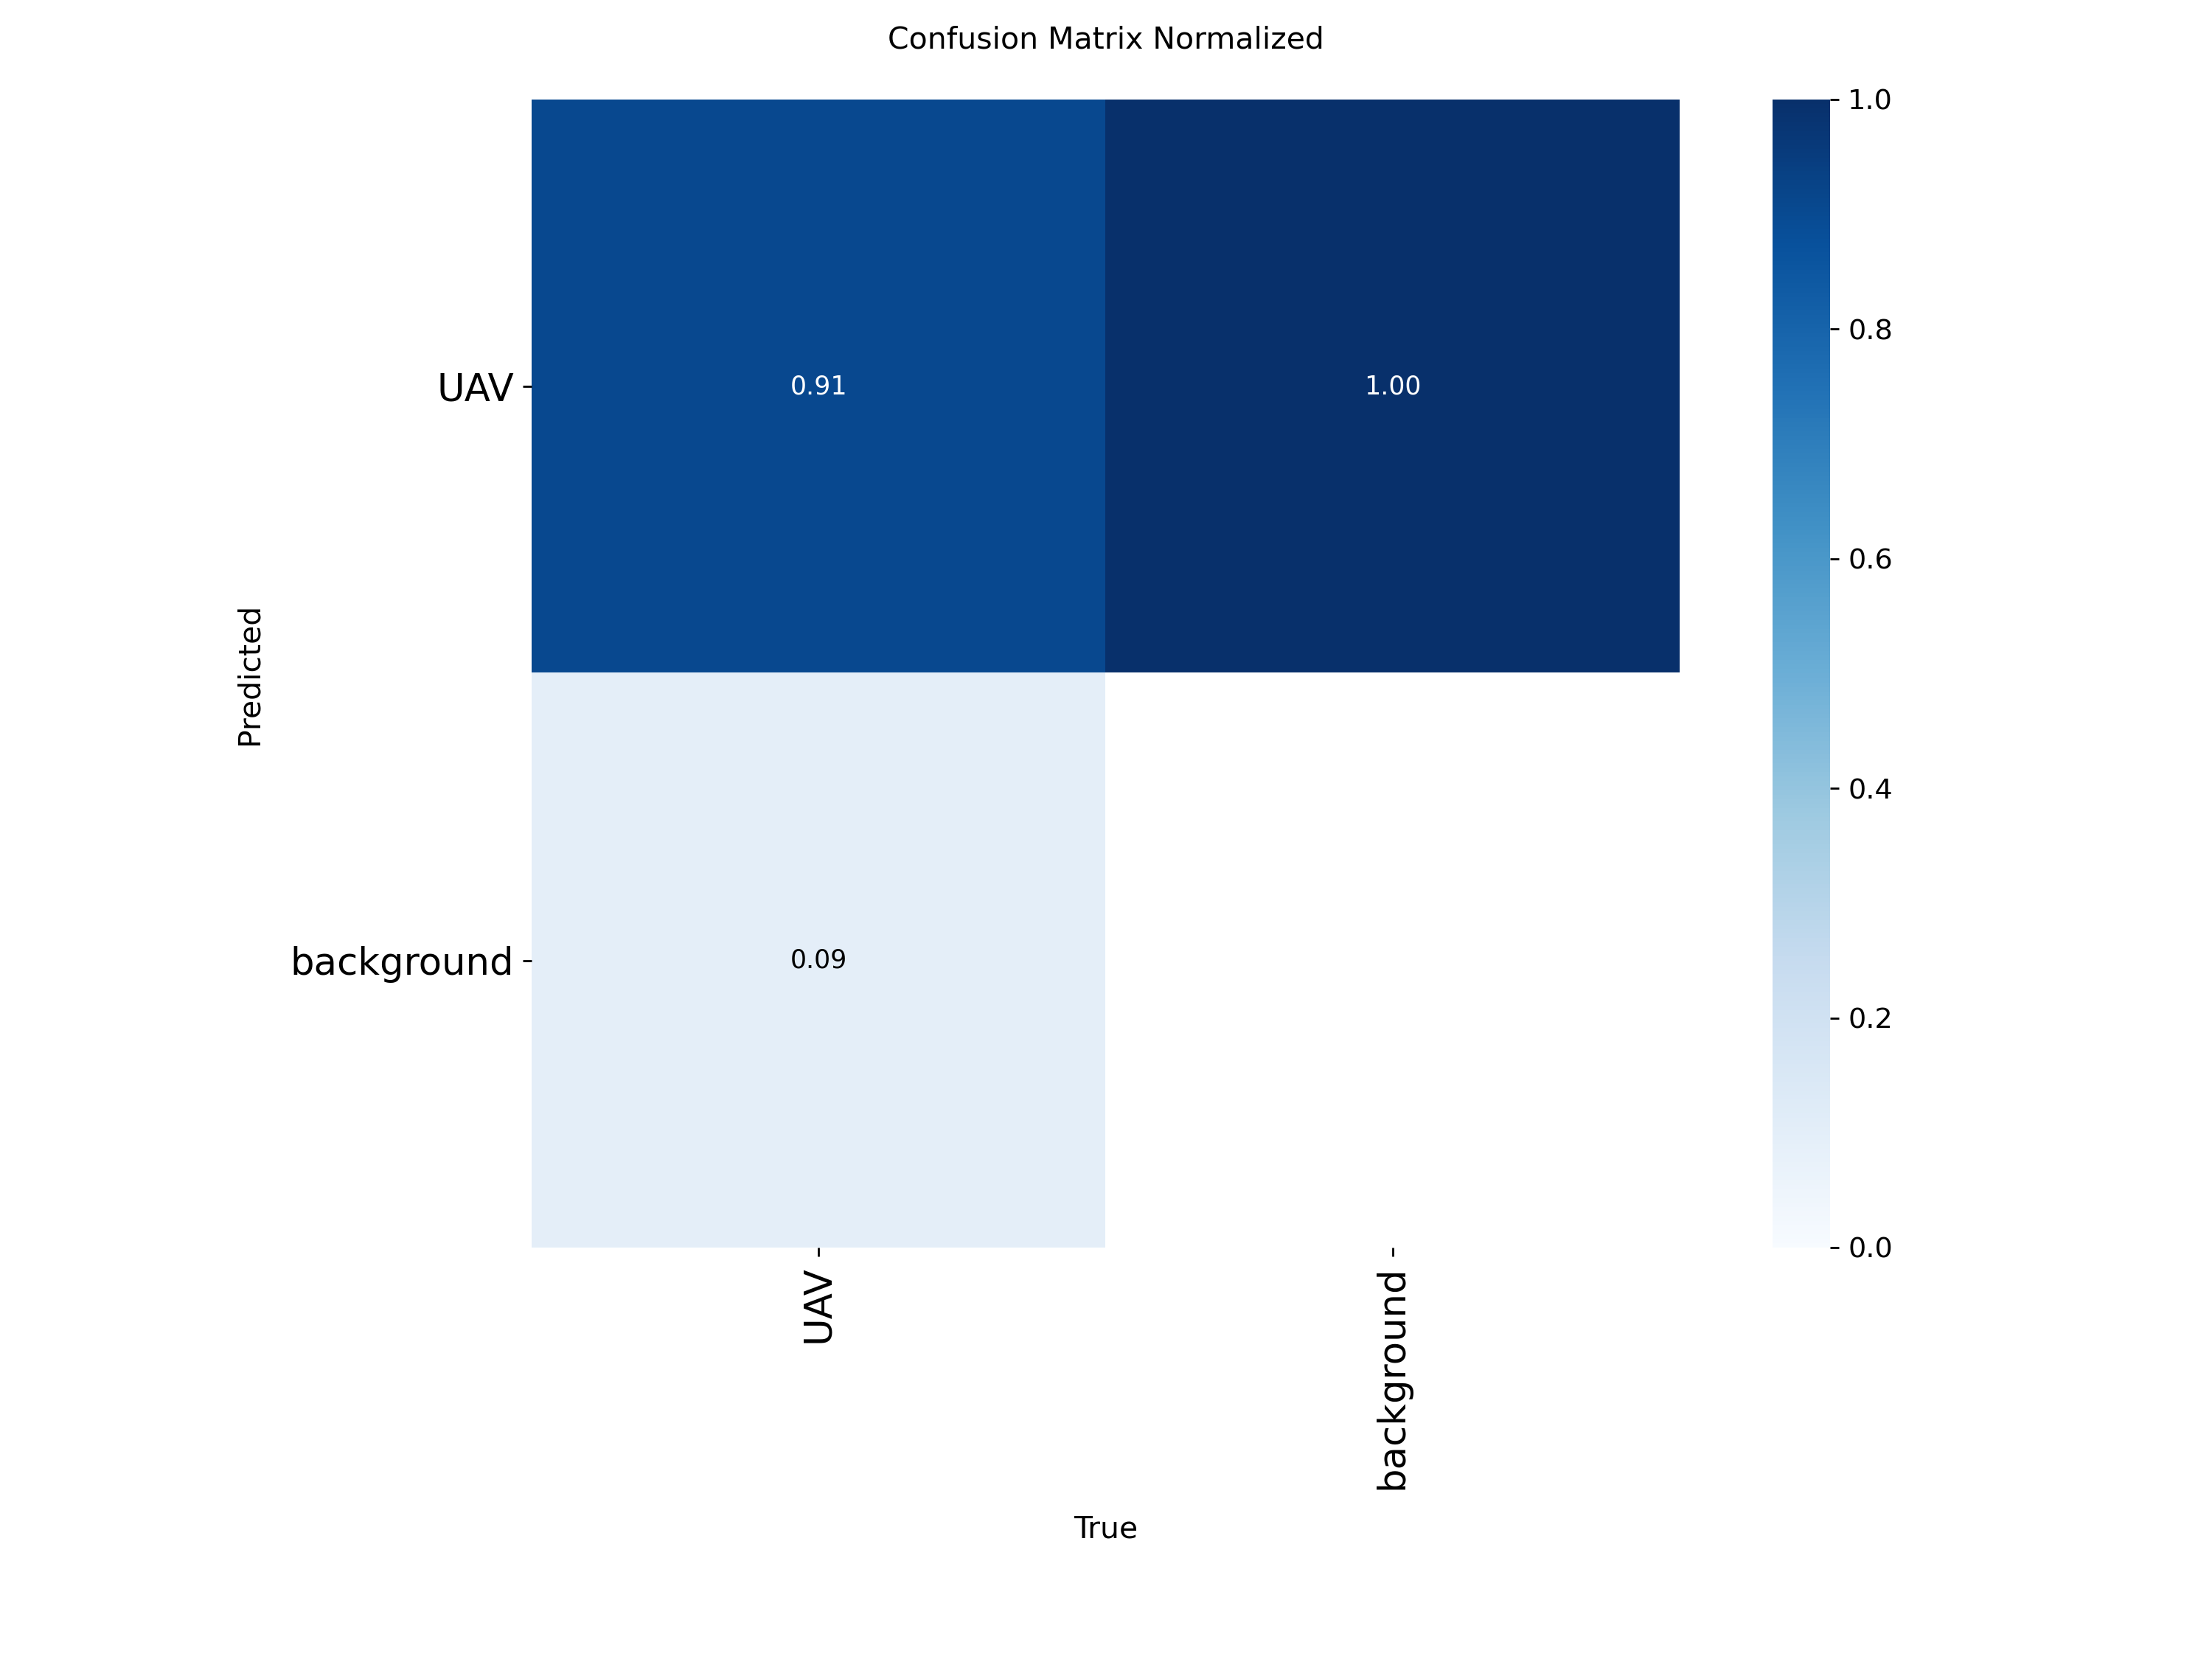

In [ ]:
EXECUTAR_AVALIACAO = False
CIENTE_DAS_LIMITACOES = False
SPLIT = 'test'  # 'val' para validação; 'test' para avaliação final
if EXECUTAR_AVALIACAO:
    assert CIENTE_DAS_LIMITACOES, 'Leia as limitações dos dados e altere CIENTE_DAS_LIMITACOES para True.'
    assert SPLIT in ('val', 'test')
    params = dict(data=str(DATA_YAML), split=SPLIT, imgsz=640, batch=16,
                  device=DEVICE, workers=2, conf=0.001, iou=0.7, max_det=300,
                  half=False, rect=True, augment=False, plots=True,
                  project=str(LOCAL_OUTPUT), name=f'avaliacao_{EXPERIMENTO}_{SPLIT}', exist_ok=False)
    metrics = model.val(**params)
    report = {'environment': ENV, 'parameters': params,
              'metrics': {k: float(v) for k, v in metrics.results_dict.items()},
              'speed_ms_per_image': metrics.speed,
              'dataset_issues': MANIFEST['issues'],
              'protocol': 'Divisão original preservada. Uma imagem idêntica entre treino e teste; teste não totalmente independente.'}
    dest = Path(metrics.save_dir)
    salvar_matrizes_com_percentuais(metrics.confusion_matrix.matrix, dest)
    (dest/'relatorio.json').write_text(json.dumps(report, ensure_ascii=False, indent=2, default=str))
    pd.DataFrame([report['metrics']]).to_csv(dest/'metricas.csv', index=False)
    display(pd.DataFrame([report['metrics']]))
    for p in sorted(dest.glob('*.png')):
        display(Image(filename=str(p), width=700))
else:
    print('Avaliação completa desativada. Nenhum treinamento foi iniciado.')


### 6.1 Testar as três imagens externas

Esta etapa compara os modelos E1, E2 e E3 nas mesmas três imagens externas utilizadas nos experimentos: `dji-t50.jpg`, `escolher-camera-para-drone.jpg.webp` e `images.jpeg`. Os arquivos originais estão incluídos no pacote.

Para executar, altere `EXECUTAR_EXTERNAS = False` para `True` e rode a célula. Serão geradas as imagens com as caixas previstas, uma tabela de contagens e os registros de coordenadas e confiança. A tabela preserva o nome de cada entrada e informa o nome do arquivo de saída correspondente.

Os testes usam tamanho de entrada de 640, confiança mínima de 0,25 e IoU de NMS de 0,70. Esses parâmetros ficam registrados junto aos resultados. A comparação é **qualitativa**: sem caixas de referência anotadas, não são calculados acurácia, mAP ou revocação. Os escores de confiança não representam essas métricas.


0: 640x640 3 UAVs, 1266.7ms
1: 640x640 3 UAVs, 1266.7ms
2: 640x640 3 UAVs, 1266.7ms
Speed: 73.2ms preprocess, 1266.7ms inference, 24.7ms postprocess per image at shape (1, 3, 640, 640)
Results saved to /content/tcc_deteccao_7724268b/resultados/20260924T173813Z_c71ed332/externas_b8f77b10/E1
3 labels saved to /content/tcc_deteccao_7724268b/resultados/20260924T173813Z_c71ed332/externas_b8f77b10/E1/labels

0: 640x640 1 UAV, 219.3ms
1: 640x640 1 UAV, 219.3ms
2: 640x640 1 UAV, 219.3ms
Speed: 6.0ms preprocess, 219.3ms inference, 0.8ms postprocess per image at shape (1, 3, 640, 640)
Results saved to /content/tcc_deteccao_7724268b/resultados/20260924T173813Z_c71ed332/externas_b8f77b10/E2
3 labels saved to /content/tcc_deteccao_7724268b/resultados/20260924T173813Z_c71ed332/externas_b8f77b10/E2/labels

0: 640x640 1 UAV, 210.3ms
1: 640x640 1 UAV, 210.3ms
2: 640x640 1 UAV, 210.3ms
Speed: 3.9ms preprocess, 210.3ms inference, 0.6ms postprocess per image at shape (1, 3, 640, 640)
Results saved to /co

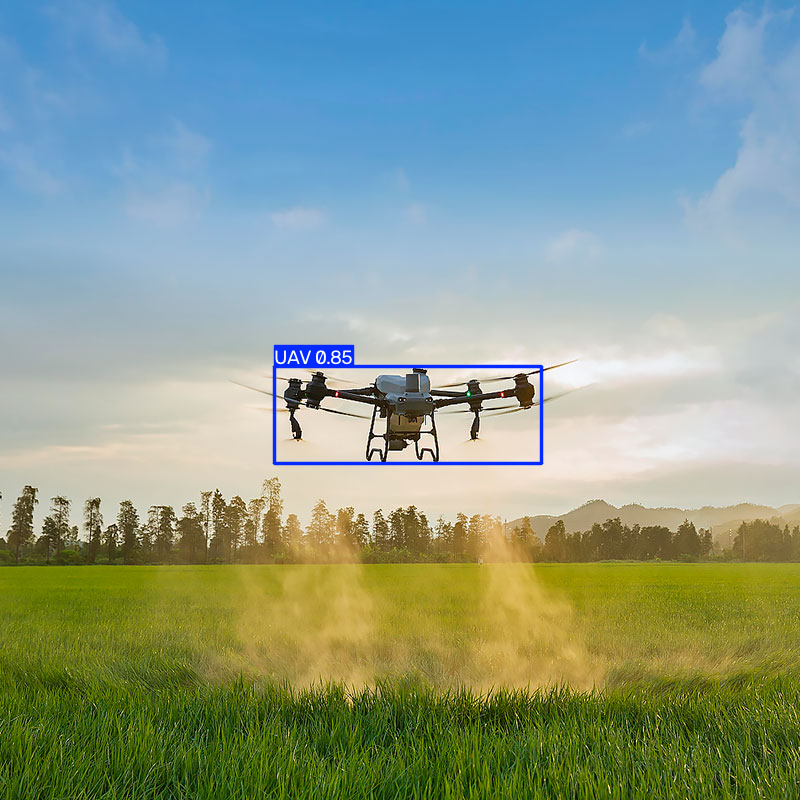

E3 escolher-camera-para-drone.jpg.webp


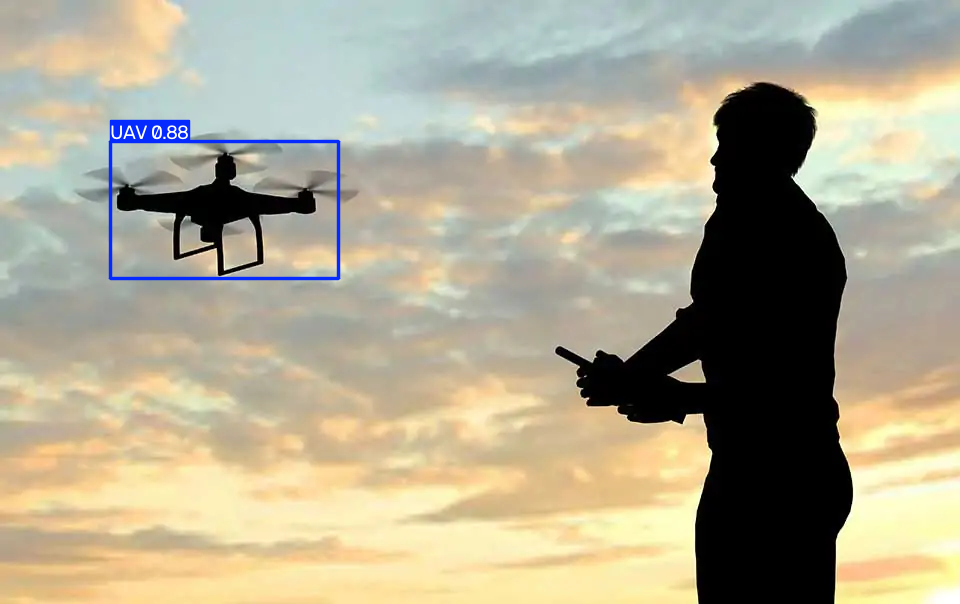

E3 images.jpeg


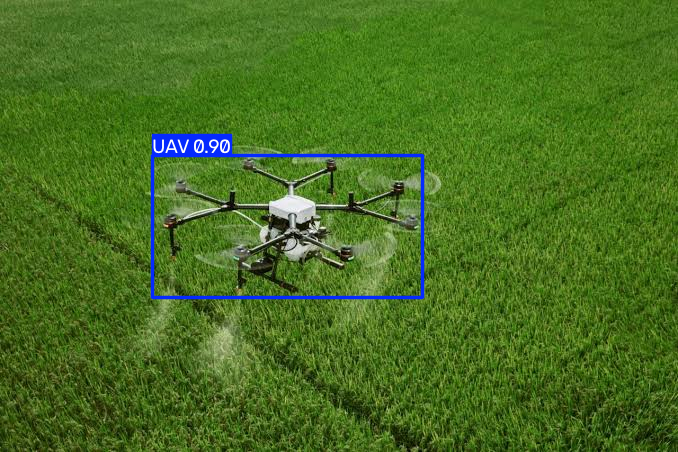

,experimento,arquivo,arquivo_saida,caixas,confiancas
0,E1,dji-t50.jpg,image0.jpg,3,"[0.8289325833320618, 0.7835902571678162, 0.523..."
1,E1,escolher-camera-para-drone.jpg.webp,image1.jpg,3,"[0.9798690676689148, 0.3999794125556946, 0.291..."
2,E1,images.jpeg,image2.jpg,3,"[0.9900683760643005, 0.9501748085021973, 0.272..."
3,E2,dji-t50.jpg,image0.jpg,1,[0.8131908178329468]
4,E2,escolher-camera-para-drone.jpg.webp,image1.jpg,1,[0.938386857509613]
5,E2,images.jpeg,image2.jpg,1,[0.8912942409515381]
6,E3,dji-t50.jpg,image0.jpg,1,[0.8467932343482971]
7,E3,escolher-camera-para-drone.jpg.webp,image1.jpg,1,[0.8770896196365356]
8,E3,images.jpeg,image2.jpg,1,[0.8997329473495483]


Resultados externos: /content/tcc_deteccao_7724268b/resultados/20260924T173813Z_c71ed332/externas_b8f77b10


In [ ]:
EXECUTAR_EXTERNAS = False
if EXECUTAR_EXTERNAS:
    from PIL import Image as PILImage
    expected = {
        'dji-t50.jpg': '3721b93923ee2b2237fbf6ec110e3f2f2f95fc8f7dcf648e3c8d5e8347a00761',
        'escolher-camera-para-drone.jpg.webp': '25ec339ae574a5039cdeff8bd3ee40b39d6ff288e79931797ab74a2d9448bb59',
        'images.jpeg': '0ea8b6533d0f27906caee6244c340eeb3b49fa1882005805d3ef3557ecde1e76'}
    input_dir = WORK/'entradas_externas'
    input_dir.mkdir(exist_ok=True)
    for name, digest in expected.items():
        source = ROOT/'entradas_externas'/name
        assert source.is_file(), f'Imagem ausente: {name}'
        assert sha256_file(source) == digest, f'Imagem diferente da original: {name}'
        shutil.copy2(source, input_dir/name)
    ext_dir = LOCAL_OUTPUT/('externas_'+uuid.uuid4().hex[:8])
    ext_dir.mkdir()
    summary, boxes, checkpoints = [], [], {}
    for experiment, folder in RUNS.items():
        checkpoint = ROOT/'runs/detect'/folder/'weights/best.pt'
        checkpoints[experiment] = sha256_file(checkpoint)
        ext_model = YOLO(str(checkpoint))
        ext_params = dict(source=[str(input_dir/n) for n in expected], imgsz=640,
                          conf=0.25, iou=0.7, max_det=300, device=DEVICE,
                          half=False, augment=False, save=True, save_txt=True,
                          save_conf=True, project=str(ext_dir), name=experiment, exist_ok=False)
        for source_name, result in zip(expected, ext_model.predict(**ext_params)):
            result_name = Path(result.path).name
            confidences = result.boxes.conf.cpu().tolist()
            summary.append({'experimento':experiment, 'arquivo':source_name, 'arquivo_saida':result_name,
                            'caixas':len(confidences), 'confiancas':json.dumps(confidences)})
            for xyxy, confidence, cls in zip(result.boxes.xyxy.cpu().tolist(), confidences,
                                             result.boxes.cls.cpu().tolist()):
                boxes.append({'experimento':experiment, 'arquivo':source_name, 'arquivo_saida':result_name,
                              'classe':result.names[int(cls)], 'confianca':confidence,
                              **dict(zip(['xmin','ymin','xmax','ymax'],xyxy))})
            if experiment == 'E3':
                print(experiment, source_name)
                display(PILImage.fromarray(result.plot()[...,::-1]))
    pd.DataFrame(summary).to_csv(ext_dir/'resumo.csv', index=False)
    pd.DataFrame(boxes, columns=['experimento','arquivo','arquivo_saida','classe','confianca','xmin','ymin','xmax','ymax']).to_csv(ext_dir/'caixas.csv', index=False)
    (ext_dir/'parametros.json').write_text(json.dumps({
        'environment':ENV, 'input_sha256':expected, 'checkpoint_sha256':checkpoints,
        'parameters':{'imgsz':640,'conf':0.25,'iou':0.7,'max_det':300,'device':DEVICE,'half':False,'augment':False},
        'scope':'Nova inferência qualitativa; sem anotações de referência externas. Não equivale a reprodução exata dos testes históricos.',
        'historical_folder_mapping':'Confirmado: predict a predict-5 = E1; predict-6 a predict-10 = E2; predict-11 a predict-15 = E3.'}, ensure_ascii=False, indent=2))
    display(pd.DataFrame(summary))
    print('Resultados externos:', ext_dir)
else:
    print('Testes externos desativados. Altere EXECUTAR_EXTERNAS para True para executá-los.')


## 7. Detectar em uma imagem

Execute a célula para testar o modelo selecionado na seção 4 em `test/images/00001.jpg`, uma imagem do conjunto de teste. A saída mostra as caixas previstas, a confiança e as coordenadas.

Para testar outra imagem:

1. Envie o arquivo pela seção 8.
2. Copie o caminho exibido após o envio.
3. Substitua o valor de `IMAGE_SOURCE` por esse caminho, entre aspas, e execute novamente esta célula.

`CONF = 0.25` define a confiança mínima. `NMS_IOU = 0.7` controla a supressão de caixas sobrepostas. Aumentar a confiança pode remover previsões pouco confiáveis, mas também reduzir a detecção de alvos difíceis. Mantenha os parâmetros fixos quando comparar modelos.

A imagem anotada e os registros são gravados na pasta de resultados da sessão. Mais de uma caixa sobre a mesma aeronave não significa que existam vários drones na imagem.


image 1/1 /content/tcc_deteccao_0a35823d/entradas/87ffa5a0/enxame.jpg.webp: 448x640 19 UAVs, 518.6ms
Speed: 27.6ms preprocess, 518.6ms inference, 3.7ms postprocess per image at shape (1, 3, 448, 640)
Results saved to /content/tcc_deteccao_0a35823d/resultados/20260928T030853Z_b8a67901/imagem_E3-2
1 label saved to /content/tcc_deteccao_0a35823d/resultados/20260928T030853Z_b8a67901/imagem_E3-2/labels


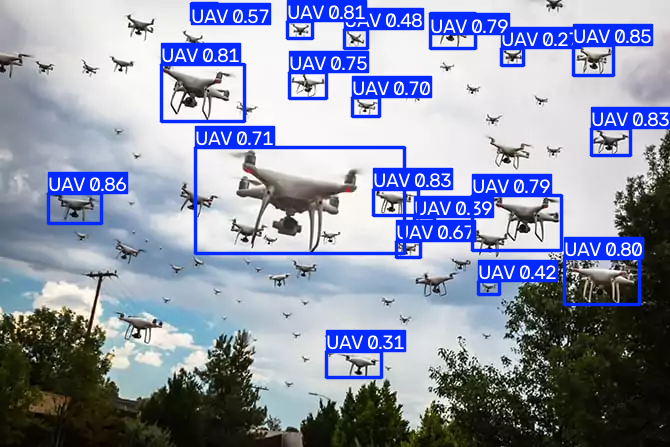

Caixas previstas: 19


,arquivo,classe,confianca,xmin,ymin,xmax,ymax
0,enxame.jpg.webp,UAV,0.856686,48.046047,193.157898,101.010963,223.361023
1,enxame.jpg.webp,UAV,0.846896,573.036011,45.513538,613.895203,75.726013
2,enxame.jpg.webp,UAV,0.834299,373.525543,189.229370,418.387299,215.766098
3,enxame.jpg.webp,UAV,0.833895,591.207520,128.845032,630.955566,155.747406
4,enxame.jpg.webp,UAV,0.813689,161.281494,64.950630,244.319565,121.276833
5,enxame.jpg.webp,UAV,0.805841,287.929779,21.960518,312.279785,38.805004
6,enxame.jpg.webp,UAV,0.796935,564.642761,258.019592,639.236206,304.732941
7,enxame.jpg.webp,UAV,0.792454,430.575928,13.288984,475.481506,48.229347
8,enxame.jpg.webp,UAV,0.790091,472.534363,195.396408,561.645447,250.756958
9,enxame.jpg.webp,UAV,0.747175,289.937439,72.437584,326.499603,98.970100


In [ ]:
IMAGE_SOURCE = ROOT/'/content/tcc_deteccao_0a35823d/entradas/87ffa5a0/enxame.jpg.webp'
CONF = 0.25
NMS_IOU = 0.7
assert Path(IMAGE_SOURCE).is_file()
image_params=dict(source=str(IMAGE_SOURCE), imgsz=640, conf=CONF, iou=NMS_IOU,
    max_det=300, device=DEVICE, half=False, augment=False, save=True,
    save_txt=True, save_conf=True, project=str(LOCAL_OUTPUT),
    name=f'imagem_{EXPERIMENTO}', exist_ok=False)
pred=model.predict(**image_params)
rows=[]
for r in pred:
    display(Image(data=__import__('PIL.Image',fromlist=['Image']).fromarray(r.plot()[...,::-1])._repr_png_()))
    for xyxy, conf, cls in zip(r.boxes.xyxy.cpu().tolist(),r.boxes.conf.cpu().tolist(),r.boxes.cls.cpu().tolist()):
        rows.append({'arquivo':Path(r.path).name, 'classe':r.names[int(cls)], 'confianca':conf,
                     **dict(zip(['xmin','ymin','xmax','ymax'],xyxy))})
dest=Path(pred[0].save_dir)
columns=['arquivo','classe','confianca','xmin','ymin','xmax','ymax']
pd.DataFrame(rows,columns=columns).to_csv(dest/'caixas.csv',index=False)
(dest/'parametros.json').write_text(json.dumps({'environment':ENV,'parameters':image_params,
    'input_sha256':sha256_file(IMAGE_SOURCE),'detections':len(rows)},indent=2,ensure_ascii=False))
print('Caixas previstas:',len(rows))
display(pd.DataFrame(rows,columns=columns))


## 8. Enviar uma imagem ou um vídeo próprio — opcional

1. Altere `ENVIAR_ARQUIVOS = False` para `True`.
2. Execute a célula e selecione apenas os arquivos que deseja testar.
3. Aguarde o envio e copie o caminho exibido para cada arquivo.
4. Para uma imagem, use esse caminho em `IMAGE_SOURCE`, na seção 7. Para um vídeo, use-o em `VIDEO_SOURCE`, na seção 9.

Os arquivos são enviados apenas ao ambiente temporário da sua sessão. Não são publicados nem adicionados ao pacote compartilhado. Use arquivos originais, sem as caixas desenhadas por uma execução anterior.

In [ ]:
ENVIAR_ARQUIVOS = True
if ENVIAR_ARQUIVOS:
    from google.colab import files
    import os
    INPUT_DIR=WORK/'entradas'/uuid.uuid4().hex[:8]
    INPUT_DIR.mkdir(parents=True, exist_ok=False)
    previous=Path.cwd()
    try:
        os.chdir(INPUT_DIR)
        uploaded=files.upload()
    finally:
        os.chdir(previous)
    for name in uploaded:
        print('Entrada:',INPUT_DIR/Path(name).name)
else:
    print('Upload manual desativado.')


Saving enxame.jpg.webp to enxame.jpg.webp
Entrada: /content/tcc_deteccao_0a35823d/entradas/87ffa5a0/enxame.jpg.webp


## 9. Detectar no vídeo externo — opcional

O arquivo `V1_base.mkv`, incluído no pacote, é o vídeo externo utilizado nos testes. Para processá-lo, altere `EXECUTAR_VIDEO = False` para `True` e execute a célula. Para outro vídeo, envie-o na seção 8 e substitua `VIDEO_SOURCE` pelo caminho informado.

O processamento utiliza todos os quadros (`vid_stride=1`) e pode levar alguns minutos. A cada 200 quadros, uma mensagem informa o andamento. Ao final, são produzidos o vídeo com as caixas previstas e dois arquivos CSV: um com as contagens por quadro e outro com as coordenadas e confidências de cada caixa.

**Quadros com previsões não são necessariamente quadros com detecção correta.** Sem anotações de referência, o vídeo permite análise qualitativa, não o cálculo de acurácia ou revocação.

O detector pode gerar um AVI. Quando o FFmpeg está disponível, a célula também cria uma cópia MP4 para visualização, preservando a saída original. Use a seção 10 para guardar os resultados.

In [ ]:
EXECUTAR_VIDEO = True
VIDEO_SOURCE = ROOT/'/content/tcc_deteccao_7724268b/entradas/7c9af9b9/visible.mp4'
if EXECUTAR_VIDEO:
    import cv2
    assert Path(VIDEO_SOURCE).is_file()
    capture = cv2.VideoCapture(str(VIDEO_SOURCE))
    source_info = {'fps':capture.get(cv2.CAP_PROP_FPS), 'frames_reported':int(capture.get(cv2.CAP_PROP_FRAME_COUNT))}
    capture.release()
    video_params = dict(source=str(VIDEO_SOURCE), stream=True, imgsz=640, conf=0.25,
        iou=0.7, max_det=300, device=DEVICE, half=False, augment=False,
        vid_stride=1, save=True, save_txt=False, save_conf=False,
        project=str(LOCAL_OUTPUT), name=f'video_{EXPERIMENTO}', exist_ok=False, verbose=False)
    log_dir = LOCAL_OUTPUT/('video_registros_'+uuid.uuid4().hex[:8])
    log_dir.mkdir()
    last_dir, frame_index, frames_with_boxes, total_boxes = None, 0, 0, 0
    with (log_dir/'quadros.csv').open('w',newline='') as counts, (log_dir/'caixas.csv').open('w',newline='') as boxes:
        cw, bw = csv.writer(counts), csv.writer(boxes)
        cw.writerow(['quadro_sequencial_1','caixas_previstas'])
        bw.writerow(['quadro_sequencial_1','classe','confianca','xmin','ymin','xmax','ymax'])
        for frame_index, r in enumerate(model.predict(**video_params), start=1):
            last_dir = Path(r.save_dir)
            n = len(r.boxes)
            frames_with_boxes += int(n > 0)
            total_boxes += n
            cw.writerow([frame_index,n])
            for xyxy, confidence, cls in zip(r.boxes.xyxy.cpu().tolist(),r.boxes.conf.cpu().tolist(),r.boxes.cls.cpu().tolist()):
                bw.writerow([frame_index,r.names[int(cls)],confidence,*xyxy])
            if frame_index % 200 == 0:
                print('Quadros processados:', frame_index, flush=True)
    assert last_dir is not None, 'Nenhum quadro processado.'
    video_report = {'environment':ENV, 'parameters':video_params,
        'input_sha256':sha256_file(VIDEO_SOURCE), 'source_info':source_info,
        'save_dir':str(last_dir), 'frames_processed':frame_index,
        'frames_with_predictions':frames_with_boxes, 'total_predicted_boxes':total_boxes,
        'limitation':'Sem anotações de referência: presença de previsões não equivale a acurácia, recall ou taxa de detecção correta.'}
    (log_dir/'parametros.json').write_text(json.dumps(video_report,indent=2,ensure_ascii=False))
    print('Resumo:', {k:video_report[k] for k in ['frames_processed','frames_with_predictions','total_predicted_boxes']})
    for output in list(last_dir.glob('*.avi')) + list(last_dir.glob('*.mp4')):
        playable = output
        if output.suffix == '.avi' and shutil.which('ffmpeg'):
            playable = output.with_name(output.stem+'_visualizacao.mp4')
            subprocess.run(['ffmpeg','-n','-loglevel','error','-i',str(output),'-an',
                '-c:v','libx264','-pix_fmt','yuv420p','-movflags','+faststart',str(playable)],check=True)
        print('Saída:',playable)
        if playable.suffix == '.mp4':
            display(Video(str(playable),embed=True,width=720))
else:
    print('Processamento de vídeo desativado.')


Results saved to /content/tcc_deteccao_7724268b/resultados/20260924T173813Z_c71ed332/video_E3-2
Resumo: {'frames_processed': 139, 'frames_with_predictions': 139, 'total_predicted_boxes': 139}
Saída: /content/tcc_deteccao_7724268b/resultados/20260924T173813Z_c71ed332/video_E3-2/visible_visualizacao.mp4


## 10. Baixar ou salvar os resultados

Execute esta etapa depois dos testes que deseja guardar. Os resultados da sessão são compactados em um ZIP com nome único, sem incluir uma nova cópia do dataset.

Escolha uma das opções na célula:

- **Baixar para o seu computador:** altere `BAIXAR_RESULTADOS` para `True`. O Colab iniciará o download do ZIP.
- **Salvar no seu próprio Google Drive:** altere `SALVAR_NO_MEU_DRIVE` para `True` e autorize o acesso solicitado pelo Colab. O arquivo será salvo em `Meu Drive/TCC-CApA/Deteccao/resultados_colab`, na conta conectada à sua sessão.

A autorização do Drive é necessária apenas para essa opção de salvamento. Ela concede acesso ao ambiente de execução; leia a solicitação antes de aceitar. Nenhum resultado pessoal é publicado automaticamente.

Se executar outros testes depois, rode esta etapa novamente para gerar um novo ZIP. Salve os arquivos antes de encerrar o ambiente temporário.

In [ ]:
BAIXAR_RESULTADOS = False
SALVAR_NO_MEU_DRIVE = False
archive_base = WORK/('resultados_'+SESSION_ID+'_'+uuid.uuid4().hex[:6])
resultados_zip = Path(shutil.make_archive(str(archive_base), 'zip', root_dir=LOCAL_OUTPUT))
print('Resultados compactados:', resultados_zip)
print('Para baixar, altere BAIXAR_RESULTADOS para True e execute novamente esta célula.')
if BAIXAR_RESULTADOS:
    from google.colab import files
    files.download(str(resultados_zip))
if SALVAR_NO_MEU_DRIVE:
    from google.colab import drive
    drive.mount('/content/drive')
    destino = Path('/content/drive/MyDrive/TCC-CApA/Deteccao/resultados_colab')/resultados_zip.name
    destino.parent.mkdir(parents=True, exist_ok=True)
    assert not destino.exists(), 'Destino já existente: não sobrescrever.'
    shutil.copy2(resultados_zip, destino)
    assert sha256_file(destino) == sha256_file(resultados_zip)
    print('Cópia salva e verificada no seu Drive:', destino)


Resultados compactados: /content/tcc_deteccao_2472243f/resultados_20260923T154848Z_89a445b1_f84688.zip
Para baixar, altere BAIXAR_RESULTADOS para True e execute novamente esta célula.
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Cópia salva e verificada no seu Drive: /content/drive/MyDrive/TCC-CApA/Deteccao/resultados_colab/resultados_20260923T154848Z_89a445b1_f84688.zip


## 11. Reproduzir um treinamento — opcional e desativado

Esta seção não é necessária para testar os modelos prontos. Ela inicia um **novo experimento**, a partir dos pesos iniciais `yolo11n.pt`, e não continua o `best.pt`. Pode consumir horas e recursos do Colab.

Os parâmetros vêm do `args.yaml` original. Os caminhos, o dispositivo e o número de processos de leitura são adaptados ao Colab e registrados. A mesma semente não garante resultados idênticos entre CPU e GPU. Execute somente após decidir se deseja preservar o protocolo original com as limitações apontadas ou elaborar, separadamente, uma versão corrigida dos dados.


In [ ]:
EXECUTAR_TREINAMENTO = False
CIENTE_DADOS_TREINO = False
TREINO_BASE = 'E3'
if EXECUTAR_TREINAMENTO:
    assert CIENTE_DADOS_TREINO, 'Leia as limitações antes de iniciar um novo treinamento.'
    assert TREINO_BASE in RUNS
    saved=yaml.safe_load((ROOT/'runs/detect'/RUNS[TREINO_BASE]/'args.yaml').read_text())
    original_args=dict(saved)
    for key in ('task','mode','model','data','project','name','save_dir','device','workers','resume','exist_ok'):
        saved.pop(key,None)
    saved.update(data=str(DATA_YAML),device=DEVICE,workers=2,resume=False,
        project=str(LOCAL_OUTPUT),name='novo_treino_'+TREINO_BASE,exist_ok=False)
    train_model=YOLO(str(ROOT/'yolo11n.pt'))
    train_model.train(**saved)
    actual=Path(train_model.trainer.save_dir)
    salvar_matrizes_com_percentuais(train_model.trainer.validator.confusion_matrix.matrix, actual)
    (actual/'proveniencia.json').write_text(json.dumps({'environment':ENV,
        'original_args':original_args,'requested_colab_args':saved,
        'initial_weights_sha256':sha256_file(ROOT/'yolo11n.pt')},indent=2,ensure_ascii=False))
    print('Treinamento novo concluído. Execute novamente a seção 10 para salvar no Drive.')
else:
    print('Treinamento desativado. Os checkpoints originais não foram modificados.')


Treinamento desativado. Os checkpoints originais não foram modificados.


## Fontes e organização dos arquivos

- **DUT Anti-UAV:** Zhao et al., *Vision-Based Anti-UAV Detection and Tracking*, DOI [10.1109/TITS.2022.3177627](https://doi.org/10.1109/TITS.2022.3177627).
- **Ultralytics:** documentação do [YOLO11](https://docs.ultralytics.com/models/yolo11/), da [avaliação](https://docs.ultralytics.com/modes/val/) e da [inferência](https://docs.ultralytics.com/modes/predict/).
- [Configuração da versão 8.4.53](https://github.com/ultralytics/ultralytics/blob/v8.4.53/ultralytics/cfg/default.yaml).
- O download público utiliza [gdown 5.2.0](https://pypi.org/project/gdown/5.2.0/).

O pacote reúne as imagens e os rótulos YOLO das três divisões, os arquivos `best.pt` dos experimentos E1, E2 e E3, os pesos iniciais `yolo11n.pt`, as configurações, os CSVs e gráficos dos treinamentos, as três imagens externas e `V1_base.mkv`. O manifesto registra a integridade dos arquivos e as limitações dos dados.

As imagens, anotações e pesos foram preservados. Os caminhos dos arquivos `args.yaml` foram adequados à distribuição, sem alterar os hiperparâmetros. Os XMLs de origem, os arquivos `last.pt` e as saídas históricas `predict*` não são necessários para executar este notebook e não integram o pacote público. Os direitos e as condições de uso das fontes originais devem ser respeitados.